# Estimating Fatigue from Facial Video during Incremental Cycling

**Part B — Group project (Computer Vision, Courses 1–3).** Authors: *(names)* — Master 2 Health, Sport & AI.

**Design.** Two participants (the authors), each performing two maximal incremental cycling tests with the same
protocol (rest ≈ 2 min, warm-up 3 min, 1-min stages to exhaustion, recovery): **v1** with the gas-exchange mask
(VT1, VT2, V̇O₂max), where only the upper face is visible, and **v2** without mask, where the whole face is
visible. Three of the four tests were filmed; one masked video starts at stage 4. ECG and perceived exertion
(Borg CR10, at the end of each stage) are recorded in every test. The notebook detects the face
(Viola–Jones), stabilises it, extracts features in regions of interest, aggregates them per second and tests
whether they change with effort and track Borg CR10, heart rate and the intensity domains given by VT1 and VT2.

| § | Content | § | Content |
|---|---|---|---|
| 0 | Fatigue, facial signs, hypotheses, outcomes | 7 | Descriptive statistics and time course |
| 1 | Setup and parameters | 8 | Rest vs effort vs recovery |
| 2 | Data | 9 | Dose–response, **primary outcome**, intensity domains |
| 3 | Face detection, ROIs, per-frame features | 10 | Unmasked vs masked test at matched stages |
| 4 | ECG and synchronisation | 11 | Correlations between features |
| 5 | Quality control | 12 | Recovery kinetics |
| 6 | Per-second features → `features.csv` | 13–14 | Discussion, reproducibility |

## 0. Fatigue, facial signs, hypotheses and outcomes

### 0.1 What we mean by "fatigue"
"Fatigue" is not a single variable. Enoka and Duchateau (2016) describe it as a symptom in which physical and
cognitive function is limited by the interaction between **performance fatigability** (decline in an objective
measure of performance) and **perceived fatigability** (change in the sensations that regulate the integrity of
the performer). Four meanings are usually distinguished:

* **Muscular (neuromuscular) fatigue** — exercise-induced reduction in the ability of a muscle to produce force or
  power (Gandevia 2001). It needs a force or power test and has no specific facial signature: not measured here
  (task failure at the end of each test is our only, crude, performance marker).
* **Cardiovascular strain** — the rise in heart rate needed to meet the metabolic demand; strictly internal load,
  but the main objective marker of proximity to maximal capacity. Measured with the ECG, and located relative to
  **VT1, VT2 and V̇O₂max** measured by gas exchange in the masked test (v1).
* **Mental fatigue** — caused by prolonged demanding cognitive activity (Marcora et al. 2009); not induced by a
  10-minute ramp. Slow blinks and eyelid closure belong to the drowsiness literature, not to exercise.
* **Perceived exertion** — "the feeling of how heavy and strenuous a physical task is" (Borg 1998), rated on the
  Borg CR10 scale at the end of each stage.

**Operational definition.** "Fatigue" = the **acute exertion** accumulated during a maximal incremental test,
measured as **cardiovascular strain** (ECG heart rate, intensity domain) and **perceived exertion** (Borg CR10).
Facial signs should reflect it through ventilation (mouth opening, breathing rate), skin blood flow and
thermoregulation (redness, sweat) and effort-related facial actions. Head motion is a mechanical control.

### 0.2 Facial signs

| Sign | Status | Evidence | CV feature (course) | Visible with mask |
|---|---|---|---|---|
| Mouth opening | **key — primary outcome** | *Mouth open* had the highest repeated-measures correlation with RPE (r = 0.70) and, with *jaw drop*, best predicted RPE in 113 students on an incremental cycling test (Timme & Brand 2020); mouth open–close rate rose with intensity (Khanal et al. 2018) | dark-cavity segmentation in a mouth ROI, opening/closing, area / face area (C1–C2); breathing rate by FFT | no |
| Redness | **key** | Forehead colour related to heart rate during a ramp in 9 students, with large between-subject heterogeneity (Khanal et al. 2022) | mean a\* (Lab) on the lower forehead (as Khanal) and cheeks; H, S, V on cheeks (C1) | forehead only |
| Head instability | **key — mechanical control** | Facial movement rises non-linearly with power (Miles et al. 2018) | box jitter (C3), optical flow split into rigid/non-rigid (C4) | yes |
| Blink rate | exploratory | Blinks detected with Viola–Jones (96 %) during sub-maximal cycling (Khanal et al. 2018) | eye cascade, runs of missed detections | yes |
| Frowning | exploratory | *Nose wrinkle* tracked the decline in affective valence rather than RPE; *brow furrow* r = 0.17 with RPE (Timme & Brand 2020) | Sobel gradient energy in the glabella (C3) | yes |
| Sweat | exploratory | Plausible (thermoregulation), not tested in the three papers | % specular pixels (high V, low S) on the forehead, opening (C1–C2) | yes |
| Eye openness (box h/w) | **discarded** | Haar windows have a fixed aspect ratio: h/w is constant by construction (§5) | — | — |
| Pallor | merged | Same colour axis as redness | S and V on cheeks | — |
| Eyebrow position, asymmetry, texture | discarded | Displacement < box jitter; no rationale in healthy subjects; non-specific | — | — |
| Motion blur | **quality control** | Driven by pedalling, not by fatigue | variance of the Laplacian → frame exclusion | — |

### 0.3 Hypotheses (declared before looking at the data)
* **H1 (ventilatory)** — mouth-opening area increases with stage and with Borg CR10, more steeply above VT1 and VT2
  (transition from nose to mouth breathing, as suggested by Timme & Brand 2020), and stays elevated in early recovery.
* **H2 (skin blood flow)** — forehead redness increases with a lag behind heart rate.
* **H3 (mechanical control)** — head instability rises with power and returns to baseline as soon as pedalling stops.

### 0.4 Outcomes (pre-specified)
**Primary outcome** — within-test Spearman correlation between **mouth-opening area** (mean of the last 30 s of each
stage, rest = stage 0) and **Borg CR10** in each test without mask (v2), with 95 % CI and permutation p-value,
pooled over the participants with the repeated-measures correlation used by Timme & Brand (2020).
Hypothesis ρ > 0; one pre-specified association, hence no multiplicity correction.

**Secondary outcomes** — (1) change of each feature between rest, effort and recovery (Cliff's δ, 95 % CI; Holm
within the key family); (2) features across the intensity domains delimited by VT1 and VT2 and their correlation
with power, heart rate and, if provided, V̇O₂; (3) upper-face features in the unmasked vs the masked test of the
same participant at matched stages (same external load); (4) half-recovery times, mechanical vs physiological.
All other analyses are exploratory.

## 1. Setup and parameters
One `PARAMS` dictionary for every sequence (saved to `params.json`). `DEMO = True` runs the notebook on synthetic
data (`tools/make_synthetic_session.py`) to test the code before filming.

In [1]:
import os, sys, json, time, datetime, hashlib, platform, warnings
from collections import deque

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from matplotlib.colors import LinearSegmentedColormap
from scipy import signal, stats
from scipy.ndimage import maximum_filter1d

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)

DEMO = True                 # True: synthetic demo data; False: your own recordings in data/
ANONYMIZE_FIGURES = True    # pixelate faces in figures (set False only to check ROI placement locally)
SEED = 42

ROOT = os.path.abspath(".")
DATA_DIR = os.path.join(ROOT, "data_demo" if DEMO else "data")
OUT_DIR = os.path.join(ROOT, "outputs_demo" if DEMO else "outputs")
FIG_DIR, TAB_DIR, CACHE_DIR = (os.path.join(OUT_DIR, d) for d in ("figures", "tables", "cache"))
for d in (FIG_DIR, TAB_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

PARAMS = dict(
    # Viola-Jones (detection on a frame downscaled to det_width; features at full resolution) and stabilisation
    det_width=480, scale_factor=1.1, min_neighbors=5, min_face_frac=0.20, full_search_every=30,
    smooth_n=9, max_hold_frames=12,
    # regions of interest: fractions (x0, y0, x1, y1) of the stabilised face box
    roi=dict(forehead=(0.30, 0.08, 0.70, 0.22), cheek_l=(0.14, 0.52, 0.34, 0.70), cheek_r=(0.66, 0.52, 0.86, 0.70),
             glabella=(0.44, 0.24, 0.56, 0.40), mouth=(0.27, 0.66, 0.73, 0.97), eyes=(0.05, 0.20, 0.95, 0.58)),
    # colour (8-bit OpenCV): YCrCb skin box (Chai & Ngan 1999, Cr widened for flushing), gray-card reference
    skin_cr=(133, 180), skin_cb=(77, 135), min_skin_frac=0.20, ref_init_s=2.0,
    shine_v_min=220, shine_s_max=60,          # specular pixels
    mouth_dark_k=0.30,                        # mouth cavity = darker than k x cheek brightness (lips excluded)
    eye_min_neighbors=6, eye_width_px=200, blink_dur_s=(0.06, 0.50), blink_win_s=30,
    tex_size=64, flow_size=128, sharp_rel_min=0.5,
    br_band_hz=(0.15, 1.20), br_win_s=20, br_min_area=0.3, br_peak_ratio=3.0,     # breathing rate; mouth open if area >= 0.3 %
    ecg_band_hz=(5.0, 15.0), rr_range_s=(0.27, 2.0), rr_max_dev=0.20, hr_max_gap_s=3.0,
    # analysis windows (s) and statistics
    rest_window_s=120, effort_window_s=60, recovery_window_s=120, stage_window_s=30, min_stage_s=15,
    block_s=10, min_valid_s=7, n_boot=2000, n_perm=9999,
)
FEATURE_INFO = {   # name: (label, unit, family, visible under the gas-exchange mask)
    "mouth_area": ("Mouth opening area", "% face area", "key", False),
    "forehead_a": ("Forehead redness a*", "a* units", "key", True),
    "head_jitter": ("Head instability (box jitter)", "% face width", "key", True),
    "br_mouth": ("Breathing rate (mouth)", "breaths/min", "exploratory", False),
    "mouth_open_pct": ("Mouth open (share of time)", "% of time", "exploratory", False),
    "cheek_a": ("Cheek redness a*", "a* units", "exploratory", False),
    "cheek_hue": ("Cheek hue H", "deg", "exploratory", False),
    "cheek_sat": ("Cheek saturation S", "%", "exploratory", False),
    "cheek_val": ("Cheek value V", "%", "exploratory", False),
    "shine_frac": ("Shiny forehead (sweat)", "% pixels", "exploratory", True),
    "glabella_grad": ("Glabella gradient (frown)", "a.u.", "exploratory", True),
    "flow_rigid": ("Head motion (rigid flow)", "% face width/s", "exploratory", True),
    "flow_nonrigid": ("Facial motion (non-rigid flow)", "% face width/s", "exploratory", True),
    "blink_rate": ("Blink rate", "blinks/min", "exploratory", True),
    "hr_ecg": ("ECG heart rate", "bpm", "reference", True),
}
FEATURES = [f for f in FEATURE_INFO if f != "hr_ecg"]
ALL = FEATURES + ["hr_ecg"]
KEY = [f for f in FEATURES if FEATURE_INFO[f][2] == "key"]
FRAME_COLS = ["raw_cx", "raw_cy", "box_x", "box_y", "box_w", "box_h", "forehead_a", "skin_frac", "cheek_a", "cheek_hue",
              "cheek_sat", "cheek_val", "shine_frac", "mouth_area", "eyes_n", "eye_aspect", "glabella_grad", "sharpness",
              "flow_rigid", "flow_nonrigid"]
PARAM_HASH = hashlib.md5(json.dumps(PARAMS, sort_keys=True).encode()).hexdigest()[:8]
json.dump(dict(PARAMS=PARAMS, SEED=SEED, DEMO=DEMO), open(os.path.join(OUT_DIR, "params.json"), "w"), indent=2)

# Plot style: fixed colour per condition / per test, recessive grid, one axis per panel.
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COND = {"rest": "#2a78d6", "effort": "#eb6834", "recovery": "#1baf7a"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("bluered", ["#1c5cab", "#86b6ef", "#f0efec", "#ee9b9a", "#b8302f"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": INK2,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "lines.linewidth": 1.5, "legend.frameon": False, "figure.dpi": 110})


def show(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()


def label(f):
    return ("★ " if FEATURE_INFO[f][2] == "key" else "") + FEATURE_INFO[f][0]


print("OpenCV", cv2.__version__, "| params", PARAM_HASH, "| data:", DATA_DIR)
assert hasattr(cv2, "CascadeClassifier"), ("this OpenCV has no Viola-Jones detector (removed in OpenCV 5): run  "
                                          '%pip install "opencv-python>=4.8,<5"  in a cell, then restart the kernel')
print("mouth threshold:", PARAMS["mouth_dark_k"], "x cheek brightness (mouth area must be about 0 at rest)")

OpenCV 4.12.0 | params fa29e47a | data: /home/claude/fatigue-video/data_demo
mouth threshold: 0.3 x cheek brightness (mouth area must be about 0 at rest)


## 2. Data
**`data/tests.xlsx`** (template: `data/tests_template.xlsx`) describes the recordings; the videos are never cut.
* Sheet `tests` — one row per test: `session_id, subject_id, video_file, ecg_file, mask` (1 = gas-exchange mask:
  lower-face features are discarded); video times typed as `mm:ss` — `t_rest_start, t_warmup_start, t_first_stage,
  t_effort_end, t_recovery_end` — with `first_stage` (number of the first stage whose start is in the video) and
  `stage_s` (stage duration); `ecg_offset_s` (**t_video = t_ecg + offset**, §4); `vt1_W, vt2_W` (power at the
  thresholds, once per subject); optional `ecg_fs, ref_roi, face_box` (`x,y,w,h` as fractions of the upright
  frame) and `rotate` (0 / 90 / 180 / 270° clockwise; empty = found automatically, §3).
  Every stage is derived from `t_first_stage` and `stage_s`; what is not in the video is left empty; a test without
  video (gas exchange only) has no `video_file`.
* Sheet `paliers` — one row per segment and test: `session_id, palier (REPOS, WARMUP, P1 … Pn, RECUP), power_W,
  borg_cr10` and, for the masked test, the stage means `vo2, ve, bf` of the metabolic cart.

Without `tests.xlsx` the same tables are read from `sessions.csv`, `segments.csv` and `cpet_stages.csv` (format of
the synthetic demo).

Analysis windows, identical for every test (30 s–2 min as required): **rest** = last 120 s of rest, **effort** =
last 60 s of exercise, **recovery** = first 120 s after exercise, **stage** = last 30 s of each stage. The warm-up
is labelled but not analysed.

In [2]:
def seconds(v):
    """Video time typed as mm:ss, h:mm:ss or seconds -> seconds (None if empty)."""
    if isinstance(v, datetime.time):                               # Excel stored 02:05 as a clock time: read it as mm:ss
        return float(v.hour * 60 + v.minute if v.second == 0 else v.hour * 3600 + v.minute * 60 + v.second)
    if v is None or pd.isna(v) or str(v).strip() == "":
        return None
    return float(sum(float(x) * 60 ** k for k, x in enumerate(reversed(str(v).replace(",", ".").split(":")))))


def load_tests_xlsx(path):
    """Sessions (filmed tests), segments in video time and CPET stage means from the two sheets of tests.xlsx."""
    T, P = (pd.read_excel(path, sheet_name=s).dropna(how="all") for s in ("tests", "paliers"))
    T, P = (d[d.session_id.notna() & ~d.session_id.astype(str).str.upper().str.startswith("EXEMPLE")].copy() for d in (T, P))
    for d in (T, P):
        d["session_id"] = d.session_id.astype(str).str.strip()
    T["subject_id"] = T.subject_id.astype(str).str.strip()
    T[["vt1_W", "vt2_W"]] = T.groupby("subject_id")[["vt1_W", "vt2_W"]].transform("first")    # typed once per subject
    P = P.dropna(subset=["power_W", "borg_cr10"], how="all").copy()
    code = P.palier.astype(str).str.strip().str.upper()
    P["condition"] = np.select([code.isin(["REPOS", "REST"]), code.str.contains("WARM|CHAUF"), code.str.startswith("REC")],
                               ["rest", "warmup", "recovery"], "effort")
    P["stage"] = pd.to_numeric(code.str.lstrip("P"), errors="coerce")                         # "P7" or "7" -> 7
    eff = P.condition == "effort"
    pmax = eff & P.stage.isna()                                                                # "PMAX" = last stage
    P.loc[pmax, "stage"] = (P[eff].groupby("session_id").stage.transform("max") + 1).reindex(P.index)[pmax]
    rows = []
    for r in T[T.video_file.notna()].itertuples():
        pal, L = P[P.session_id == r.session_id], 60.0 if pd.isna(r.stage_s) else float(r.stage_s)
        t0, t_end = seconds(r.t_first_stage), seconds(r.t_effort_end)
        assert t0 is not None and t_end is not None, f"{r.session_id}: t_first_stage and t_effort_end are required"
        t1 = t0 - ((1 if pd.isna(r.first_stage) else int(r.first_stage)) - 1) * L     # start of stage 1 (< 0: before the video)
        tr, tw = seconds(r.t_rest_start), seconds(r.t_warmup_start)
        stages = sorted(pal[pal.condition == "effort"].stage.dropna().astype(int))
        segs = [("rest", 0, tr, t1 if tw is None else tw), ("warmup", np.nan, tw, t1)]
        segs += [("effort", k, t1 + (k - 1) * L, min(t1 + k * L, t_end)) for k in stages]
        segs += [("recovery", -1, t_end, seconds(r.t_recovery_end))]
        for cond, k, a, b in segs:
            if a is None or b is None or b <= max(a, 0):           # not in the video
                continue
            q = pal[(pal.condition == cond) & ((pal.stage == k) | (cond != "effort"))]
            power = q.power_W.iloc[0] if len(q) and pd.notna(q.power_W.iloc[0]) else (np.nan if cond == "effort" else 0)
            rows.append(dict(session_id=r.session_id, segment=f"P{k}" if cond == "effort" else cond, condition=cond, stage=k,
                             t_start_s=max(a, 0.0), t_end_s=b, power_W=power,
                             borg_cr10=q.borg_cr10.iloc[0] if len(q) else np.nan))
        over = t_end - (t1 + (stages[-1] if stages else 0) * L)
        if not stages or over > 5 or over <= -L:
            print(f"CHECK {r.session_id}: effort ends {over:+.0f} s after the end of the last stage listed in 'paliers' "
                  f"({len(stages)} stages) -> check t_first_stage, first_stage, t_effort_end and the stage rows")
    cpet = [c for c in ("vo2", "ve", "bf") if c in P and P[c].notna().any()]
    C = (P[eff].merge(T[["session_id", "subject_id"]]).dropna(subset=cpet, how="all")
         .groupby(["subject_id", "stage"])[cpet].mean().reset_index()) if cpet else None
    S = T[T.video_file.notna()].rename(columns={"video_file": "video_path", "ecg_file": "ecg_path"})
    return S, pd.DataFrame(rows), C


def opt(row, name, default=None):
    """Optional cell of a sessions.csv row (missing column, NaN or empty string -> default)."""
    v = row.get(name, default)
    return default if v is None or (isinstance(v, float) and np.isnan(v)) or str(v).strip() == "" else v


def parse_box(s):
    return None if s is None else tuple(float(v) for v in str(s).split(","))


if DEMO and not os.path.exists(os.path.join(DATA_DIR, "sessions.csv")):
    sys.path.insert(0, os.path.join(ROOT, "tools"))
    import make_synthetic_session
    make_synthetic_session.make_all(DATA_DIR, seed=1)          # two synthetic tests (15-20 min)

if os.path.exists(os.path.join(DATA_DIR, "tests.xlsx")):
    sessions, segments, CPET = load_tests_xlsx(os.path.join(DATA_DIR, "tests.xlsx"))
else:
    sessions = pd.read_csv(os.path.join(DATA_DIR, "sessions.csv"), dtype={"session_id": str, "subject_id": str})
    segments = pd.read_csv(os.path.join(DATA_DIR, "segments.csv"), dtype={"session_id": str})
    cpet_path = os.path.join(DATA_DIR, "cpet_stages.csv")
    CPET = pd.read_csv(cpet_path, dtype={"subject_id": str}) if os.path.exists(cpet_path) else None


def locate(path):
    """File typed in the workbook, looked up (ignoring case) where typed, then in data/ and in data/raw/; None if absent."""
    if path is None or pd.isna(path) or not str(path).strip():
        return None
    folder, name = os.path.split(str(path).strip())
    for d in (folder, "", "raw"):
        hit = [f for f in (os.listdir(os.path.join(DATA_DIR, d)) if os.path.isdir(os.path.join(DATA_DIR, d)) else [])
               if f.lower() == name.lower()]
        if hit:
            return os.path.join(d, hit[0])
    return None


sessions = sessions.set_index("session_id", drop=False)
typed = sessions[["video_path", "ecg_path"]].copy()
sessions["video_path"], sessions["ecg_path"] = sessions.video_path.map(locate), sessions.ecg_path.map(locate)
assert sessions.video_path.notna().all(), (f"video not found: {list(typed.video_path[sessions.video_path.isna()])}; "
                                           f"files in data/: {sorted(os.listdir(DATA_DIR))}")
assert set(segments.condition) <= {"rest", "warmup", "effort", "recovery"}, "condition: rest / warmup / effort / recovery"
for sid, r in sessions.iterrows():                             # the brief requires >= 720p and >= 25 fps
    cap = cv2.VideoCapture(os.path.join(DATA_DIR, r.video_path))
    assert cap.isOpened(), f"cannot open {r.video_path} (record in H.264 'Most Compatible', HDR off)"
    w, h, fps = (cap.get(k) for k in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT, cv2.CAP_PROP_FPS))
    print(f"{sid}: {w:.0f}x{h:.0f} at {fps:.2f} fps, {cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps:.0f} s",
          "" if min(w, h) >= 720 and fps >= 24.9 else " <-- below the brief's requirements")
    cap.release()
display(sessions.drop(columns="session_id"))
display(segments.head(12))

S01: 1280x720 at 30.00 fps, 1020 s 
S02: 1280x720 at 25.00 fps, 960 s 


,subject_id,video_path,ecg_path,ecg_fs,ecg_offset_s,ref_roi,mask,face_box,vt1_W,vt2_W,notes
session_id,,,,,,,,,,,
S01,A,raw/S01_video.mp4,raw/S01_ecg.csv,NaN,-4.0,"0.0703,0.4167,0.0938,0.1667",1,NaN,125,200,synthetic demo
S02,A,raw/S02_video.mp4,raw/S02_ecg.csv,500.0,2.5,"0.0703,0.4167,0.0938,0.1667",0,NaN,125,200,synthetic demo


,segment,condition,stage,t_start_s,t_end_s,power_W,borg_cr10,session_id
0,rest,rest,0,30,150,0,0.5,S01
1,stage01,effort,1,150,210,50,0.5,S01
2,stage02,effort,2,210,270,75,1.0,S01
3,stage03,effort,3,270,330,100,3.0,S01
4,stage04,effort,4,330,390,125,4.0,S01
5,stage05,effort,5,390,450,150,4.5,S01
6,stage06,effort,6,450,510,175,6.0,S01
7,stage07,effort,7,510,570,200,8.0,S01
8,stage08,effort,8,570,630,225,9.0,S01
9,stage09,effort,9,630,690,250,10.0,S01


## 3. Face detection, regions of interest and per-frame features
**Viola–Jones.** `detectMultiScale` scans a fixed-aspect window over an image pyramid (`scaleFactor`) and keeps
candidates with at least `minNeighbors` overlapping detections. The search is restricted to the neighbourhood of
the previous face (full frame every 30 frames or after a miss). Raw boxes jitter (scale quantisation): ROIs use the
**median of the last 9 detections**, held for up to 12 frames when detection fails. If the cascade fails under the
gas-exchange mask, give a fixed `face_box` for that session (tripod and ergometer do not move). The smallest face
searched is 20 % of the shorter side of the frame. Phone videos are sometimes stored sideways: the cascade only
finds upright faces, so each video is tried at 0, 90, 180 and 270° on 8 frames and the orientation with the most
detections is applied to every frame (or the `rotate` value typed in `tests.xlsx`).

| Feature | Region | Computation | Unit |
|---|---|---|---|
| `forehead_a`, `cheek_a` | lower forehead / cheeks, skin pixels (YCrCb box + opening) | mean a\* (Lab) | a\* |
| `cheek_hue`, `cheek_sat`, `cheek_val` | cheeks, skin pixels | circular mean of H; mean S, V (HSV) | deg, % |
| `shine_frac` | forehead | % pixels with V ≥ 220 and S ≤ 60 after 2×2 opening | % |
| `mouth_area` | mouth ROI | pixels darker than 0.30 × cheek V, opening 3×3 + closing 5×5, largest central component | % face area |
| `eyes_n`, `eye_aspect` | upper face | eye-cascade detections (0–2); h/w of the eye boxes | count, ratio |
| `glabella_grad` | glabella, resized 64×64 | mean Sobel magnitude / mean intensity | a.u. |
| `flow_rigid`, `flow_nonrigid` | face, resized 128×128 | Farnebäck flow: median vector (head) and mean residual (face) | % face width/s |
| `sharpness` | face, resized 128×128 | variance of the Laplacian (quality control) | a.u. |

With a gray card in the frame (`ref_roi`), every ROI is multiplied channel-wise by card(start) / card(t), which
removes the exposure and white-balance drift of the phone.

In [3]:
def load_cascade(name):
    for folder in (getattr(getattr(cv2, "data", None), "haarcascades", ""), os.path.join(ROOT, "cascades")):
        c = cv2.CascadeClassifier(os.path.join(folder, name))
        if not c.empty():
            return c
    raise FileNotFoundError(f"{name}: install opencv-python 4.x or copy the XML into ./cascades/")


FACE_CASCADE, EYE_CASCADE = load_cascade("haarcascade_frontalface_default.xml"), load_cascade("haarcascade_eye.xml")
K2, K3 = np.ones((2, 2), np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
K5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


ROT = {90: cv2.ROTATE_90_CLOCKWISE, 180: cv2.ROTATE_180, 270: cv2.ROTATE_90_COUNTERCLOCKWISE}


def turn(frame, rot):
    """Rotate a frame clockwise by 0, 90, 180 or 270 degrees (phone videos stored sideways)."""
    return cv2.rotate(frame, ROT[rot]) if rot else frame


def iou(a, b):
    ix = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    return ix * iy / (a[2] * a[3] + b[2] * b[3] - ix * iy + 1e-9)


class FaceTracker:
    """Viola-Jones on a downscaled gray frame (local search around the previous face) + median-of-N stabilisation."""

    def __init__(self, frame_w, frame_h, p):
        self.p, self.s = p, p["det_width"] / frame_w
        self.size = (p["det_width"], int(round(frame_h * self.s)))
        self.buf, self.missing, self.k = deque(maxlen=p["smooth_n"]), 0, 0

    def _detect(self, small, prev):
        p, x0, y0 = self.p, 0, 0
        kw = dict(minSize=(int(p["min_face_frac"] * min(self.size)),) * 2)       # fraction of the shorter side
        if prev is not None:                                       # search only around the previous face
            x, y, w, h = prev
            x0, y0 = int(max(0, x - 0.5 * w)), int(max(0, y - 0.5 * h))
            small = small[y0:int(y + 1.5 * h), x0:int(x + 1.5 * w)]
            kw = dict(minSize=(int(0.6 * w),) * 2, maxSize=(int(1.6 * w),) * 2)
        faces = FACE_CASCADE.detectMultiScale(small, scaleFactor=p["scale_factor"], minNeighbors=p["min_neighbors"], **kw)
        return [(x + x0, y + y0, w, h) for x, y, w, h in faces]

    def update(self, gray):
        """Return (raw box or None, stabilised box or None), both (x, y, w, h) in full-resolution pixels."""
        small = cv2.resize(gray, self.size, interpolation=cv2.INTER_AREA)
        prev = np.median(np.array(self.buf), axis=0) * self.s if self.buf else None
        local = prev is not None and self.k % self.p["full_search_every"] != 0
        faces = (self._detect(small, prev) if local else []) or self._detect(small, None)
        self.k += 1
        if faces:
            best = max(faces, key=lambda f: (iou(f, prev) if prev is not None else 0, f[2]))
            raw = tuple(v / self.s for v in best)
            self.buf.append(raw)
            self.missing = 0
        else:
            raw, self.missing = None, self.missing + 1
            if self.missing > self.p["max_hold_frames"]:
                self.buf.clear()
        return raw, (tuple(np.median(np.array(self.buf), axis=0)) if self.buf else None)


def find_rotation(path, p, n=8):
    """Clockwise rotation that makes the face upright: the one with most Viola-Jones detections in n frames."""
    cap, hits = cv2.VideoCapture(path), dict.fromkeys((0, 90, 180, 270), 0)
    for k in range(n):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int((k + 0.5) * cap.get(cv2.CAP_PROP_FRAME_COUNT) / n))
        ok, frame = cap.read()
        for rot in hits if ok else ():
            gray = cv2.cvtColor(turn(frame, rot), cv2.COLOR_BGR2GRAY)
            hits[rot] += FaceTracker(gray.shape[1], gray.shape[0], p).update(gray)[0] is not None
    cap.release()
    return max(hits, key=hits.get), hits


def roi(img, box, frac=(0, 0, 1, 1)):
    """Crop a ROI given as fractions (x0, y0, x1, y1) of the box (x, y, w, h), clipped to the image."""
    x, y, w, h = box
    x0, y0, x1, y1 = (max(0, int(round(v))) for v in (x + frac[0] * w, y + frac[1] * h, x + frac[2] * w, y + frac[3] * h))
    return img[y0:y1, x0:x1]


def frac_box(frame, box):
    """Box given as fractions of the frame -> pixels."""
    H, W = frame.shape[:2]
    return box[0] * W, box[1] * H, box[2] * W, box[3] * H


def skin_colour(bgr, p):
    """Mean a* (Lab), circular-mean H and mean S, V (HSV) over the skin pixels of a BGR crop."""
    if bgr.size == 0:
        return {}
    m = cv2.inRange(cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb), (0, p["skin_cr"][0], p["skin_cb"][0]),
                    (255, p["skin_cr"][1], p["skin_cb"][1]))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, K3) > 0
    if m.mean() < p["min_skin_frac"]:
        return dict(skin_frac=m.mean())
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[m].astype(float)
    ang = np.deg2rad(2 * hsv[:, 0])                               # OpenCV hue is 0-179: circular mean, red wraps at 0
    return dict(skin_frac=m.mean(), a=cv2.cvtColor(bgr, cv2.COLOR_BGR2Lab)[m][:, 1].mean() - 128.0,
                hue=np.rad2deg(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())),
                sat=hsv[:, 1].mean() / 2.55, val=hsv[:, 2].mean() / 2.55)


def mouth_area(bgr, cheek_val, face_area, p):
    """Dark mouth cavity (% of face area): threshold relative to cheek brightness, morphology, largest central blob."""
    if bgr.size == 0 or not np.isfinite(cheek_val):
        return np.nan
    m = (cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[..., 2] < p["mouth_dark_k"] * cheek_val * 2.55).astype(np.uint8)
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, K3), cv2.MORPH_CLOSE, K5)
    n, _, st, cen = cv2.connectedComponentsWithStats(m, 8)
    areas = [st[i, cv2.CC_STAT_AREA] for i in range(1, n) if 0.2 < cen[i][0] / m.shape[1] < 0.8]
    return 100.0 * max(areas, default=0) / face_area


def eyes(gray, p):
    """Number of eyes found by the eye cascade (0-2) and mean h/w of their boxes."""
    if gray.size == 0:
        return 0, np.nan
    W = p["eye_width_px"]
    g = cv2.resize(gray, (W, max(1, int(gray.shape[0] * W / gray.shape[1]))))
    found = sorted(EYE_CASCADE.detectMultiScale(g, scaleFactor=1.1, minNeighbors=p["eye_min_neighbors"],
                                                minSize=(int(0.12 * W),) * 2, maxSize=(int(0.4 * W),) * 2),
                   key=lambda e: -e[2])
    kept = []
    for e in found:
        if len(kept) < 2 and all(iou(e, k) < 0.2 for k in kept):
            kept.append(e)
    return len(kept), (np.mean([e[3] / e[2] for e in kept]) if kept else np.nan)


def frame_features(frame, gray, prev_gray, box, gain, dt, p):
    """All features of one frame given the stabilised face box."""
    R = {k: roi(frame, box, v) for k, v in p["roi"].items()}
    if gain is not None:                                           # gray-card correction of the colour ROIs
        R = {k: np.clip(v.astype(np.float32) * gain, 0, 255).astype(np.uint8) for k, v in R.items()}
    cl, cr = R["cheek_l"], R["cheek_r"]
    cheeks = cv2.hconcat([cl, cv2.resize(cr, cl.shape[1::-1])]) if cl.size and cr.size else cl
    ch, fo = skin_colour(cheeks, p), skin_colour(R["forehead"], p)
    f = dict(forehead_a=fo.get("a", np.nan), skin_frac=fo.get("skin_frac", np.nan),
             **{f"cheek_{k}": ch.get(k, np.nan) for k in ("a", "hue", "sat", "val")})
    if R["forehead"].size:
        hsv = cv2.cvtColor(R["forehead"], cv2.COLOR_BGR2HSV)
        spec = ((hsv[..., 2] >= p["shine_v_min"]) & (hsv[..., 1] <= p["shine_s_max"])).astype(np.uint8)
        f["shine_frac"] = 100.0 * cv2.morphologyEx(spec, cv2.MORPH_OPEN, K2).mean()
    f["mouth_area"] = mouth_area(R["mouth"], f["cheek_val"], box[2] * box[3], p)
    f["eyes_n"], f["eye_aspect"] = eyes(roi(gray, box, p["roi"]["eyes"]), p)
    g = roi(gray, box, p["roi"]["glabella"])
    if g.size:
        g = cv2.resize(g, (p["tex_size"],) * 2, interpolation=cv2.INTER_AREA).astype(np.float32)
        f["glabella_grad"] = float(np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1)).mean()
                                   / (g.mean() + 1))
    face = [roi(im, box) for im in (gray, prev_gray) if im is not None]
    if all(im.size for im in face):
        face = [cv2.resize(im, (p["flow_size"],) * 2, interpolation=cv2.INTER_AREA) for im in face]
        f["sharpness"] = float(cv2.Laplacian(face[0], cv2.CV_32F).var())
        if len(face) == 2 and dt > 0:
            flow = cv2.calcOpticalFlowFarneback(face[1], face[0], None, 0.5, 3, 15, 3, 5, 1.2, 0)
            rigid = np.median(flow.reshape(-1, 2), axis=0)        # head translation; the residual is facial motion
            k = 100.0 / p["flow_size"] / dt                       # px/frame on the crop -> % face width per second
            f["flow_rigid"] = float(np.hypot(*rigid) * k)
            f["flow_nonrigid"] = float(np.hypot(*np.moveaxis(flow - rigid, -1, 0)).mean() * k)
    return f


def process_video(path, p, ref_roi=None, face_box=None, cache=None, rot=0):
    """One pass over the video: detection, stabilisation and per-frame features (cached as CSV)."""
    if cache and os.path.exists(cache):
        return pd.read_csv(cache)
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    tracker, rows, prev_gray, card0, t0 = None, [], None, [], time.time()
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0
        if rows and not t > rows[-1]["t_s"]:
            t = len(rows) / fps                                   # container without usable timestamps
        frame = turn(frame, rot)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        tracker = tracker or FaceTracker(gray.shape[1], gray.shape[0], p)
        raw, box = (None, frac_box(frame, face_box)) if face_box else tracker.update(gray)
        row = dict(frame=len(rows), t_s=t, det=raw is not None or bool(face_box))
        if raw is not None:
            row.update(raw_cx=raw[0] + raw[2] / 2, raw_cy=raw[1] + raw[3] / 2)
        gain = None
        if ref_roi:                                               # gain = card over the first seconds / card now
            card = roi(frame, frac_box(frame, ref_roi)).reshape(-1, 3).mean(0)
            if t <= p["ref_init_s"]:
                card0.append(card)
            gain = (np.mean(card0, axis=0) / np.maximum(card, 1)).astype(np.float32)
        if box is not None:
            row.update(box_x=box[0], box_y=box[1], box_w=box[2], box_h=box[3])
            row.update(frame_features(frame, gray, prev_gray, box, gain, t - rows[-1]["t_s"] if rows else 0, p))
        rows.append(row)
        prev_gray = gray
    cap.release()
    df = pd.DataFrame(rows).reindex(columns=["frame", "t_s", "det"] + FRAME_COLS)
    print(f"  {len(df)} frames in {time.time() - t0:.0f} s, detection rate {df.det.mean():.1%}")
    if cache:
        df.to_csv(cache, index=False)
    return df


FRAMES, ROTATE = {}, {}
for sid, r in sessions.iterrows():
    vpath = os.path.join(DATA_DIR, r.video_path)
    rot, hits = (int(opt(r, "rotate")), None) if opt(r, "rotate") is not None else find_rotation(vpath, PARAMS)
    ROTATE[sid] = rot
    print(f"session {sid}: frames rotated by {rot}°", "(typed)" if hits is None else f"(face found in {hits[rot]} of 8 sample frames)")
    if hits is not None and not hits[rot] and opt(r, "face_box") is None:
        print("  WARNING: no face found in any orientation -> give `rotate` and `face_box` for this test in tests.xlsx")
    sig = f"{PARAM_HASH}_{os.path.getsize(vpath)}_{int(os.path.getmtime(vpath))}_{opt(r, 'ref_roi')}_{opt(r, 'face_box')}"
    cache = os.path.join(CACHE_DIR, f"{sid}_frames_{hashlib.md5((sig + f'_rot{rot}' * bool(rot)).encode()).hexdigest()[:10]}.csv.gz")
    FRAMES[sid] = process_video(vpath, PARAMS, parse_box(opt(r, "ref_roi")), parse_box(opt(r, "face_box")), cache, rot)

session S01: frames rotated by 0° (face found in 8 of 8 sample frames)


session S02: frames rotated by 0° (face found in 8 of 8 sample frames)


## 4. ECG: R-peaks, heart rate and synchronisation
The raw ECG CSV is read with automatic detection of the separator, the time column and its unit (s, ms, µs, ns;
otherwise `ecg_fs`). When the file holds several leads (12-lead export), every lead is processed and the one with
the fewest rejected RR intervals is kept. R-peaks: Pan–Tompkins-type chain (band-pass 5–15 Hz → derivative →
squaring → 150-ms moving integration → adaptive threshold), refined on the filtered signal. RR intervals outside
0.27–2.0 s or deviating more than 20 % from the local median are rejected.

**Synchronisation** (t_video = t_ecg + `ecg_offset_s`). If `ecg_offset_s` is left empty, the heart-rate peak is
aligned with the end of effort read in the video: heart rate starts to fall within a few seconds of stopping, so
the alignment is good to about ± 5 s (negligible for 30-s stage means, to keep in mind for the recovery kinetics).
For a tighter synchronisation, tap an electrode three times in front of the camera: the tap times in ECG time are
printed below and `ecg_offset_s = t_tap_video − t_tap_ecg`. As an independent check, the motion noise of the ECG
(> 40 Hz) and the head motion of the video are both driven by pedalling and must start and stop together: the lag
that maximises their correlation is printed and the two curves are overlaid in §5.

In [4]:
def load_ecg_csv(path, fs=None):
    """Return t (s from 0), the lead(s) as a DataFrame and the sampling rate; separator and time unit are detected."""
    df = None
    for kw in (dict(sep=";", decimal=","), dict(sep=","), dict(sep=None, engine="python")):
        try:
            d = pd.read_csv(path, **kw).apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
        except Exception:
            continue
        if d.shape[1] and d.notna().mean().max() > 0.9:
            df = d.dropna()
            break
    assert df is not None, f"cannot parse {path}: export a plain CSV with a header row"
    tcol = next((c for c in df if any(k in str(c).lower() for k in ("time", "t_s", "sec", "[ms]", "[ns]"))), None)
    X = df.drop(columns=[tcol] if tcol is not None else [])
    short = [str(c).split()[-1] for c in X]                        # ",80/mV 16 0 0 0 0  II" -> "II"
    X.columns = short if len(set(short)) == len(short) else X.columns
    if tcol is None:
        assert fs, "no time column in the ECG file: give ecg_fs (Hz) in tests.xlsx"
        return np.arange(len(X)) / float(fs), X, float(fs)
    t = df[tcol].values.astype(float)
    dt = np.median(np.diff(t))
    unit = next((u for u in (1.0, 1e-3, 1e-6, 1e-9) if 50 <= 1 / (dt * u) <= 5000), None)
    assert unit, f"time column '{tcol}' gives an implausible sampling rate"
    return (t - t[0]) * unit, X, 1 / (dt * unit)


def r_peaks(x, fs, p):
    """Indices of the R-peaks and the band-passed ECG (R waves positive)."""
    y = signal.filtfilt(*signal.butter(3, np.array(p["ecg_band_hz"]) / (fs / 2), "band"), x)
    if abs(np.percentile(y, 0.1)) > abs(np.percentile(y, 99.9)):
        y = -y
    w = max(1, int(0.15 * fs))
    integ = np.convolve(np.gradient(y) ** 2, np.ones(w) / w, mode="same")
    thr = np.maximum(0.3 * maximum_filter1d(integ, int(4 * fs)), 0.02 * np.percentile(integ, 99))
    pk, _ = signal.find_peaks(integ, height=thr, distance=int(0.27 * fs))
    half, keep = int(0.10 * fs), []
    for q in np.unique([max(0, q - half) + np.argmax(y[max(0, q - half):q + half]) for q in pk]):
        if not keep or (q - keep[-1]) / fs >= 0.27:               # refractory period on the refined peaks
            keep.append(q)
        elif y[q] > y[keep[-1]]:
            keep[-1] = q
    return np.array(keep, int), y


def heart_rate(t_r, t_max, offset, p):
    """RR table (with rejection flag) and mean heart rate for each second of VIDEO time (NaN across long gaps)."""
    rr = pd.DataFrame(dict(t=t_r[1:] + offset, rr=np.diff(t_r)))
    med = rr.rr.rolling(11, center=True, min_periods=3).median()
    rr["ok"] = rr.rr.between(*p["rr_range_s"]) & ((rr.rr - med).abs() / med <= p["rr_max_dev"])
    g = rr[rr.ok]
    grid = np.arange(0, int(t_max) + 1, 0.25)
    hr = np.interp(grid, g.t, 60 / g.rr, left=np.nan, right=np.nan)
    i = np.clip(np.searchsorted(g.t.values, grid), 1, len(g) - 1)
    hr[(g.t.values[i] - g.t.values[i - 1]) > p["hr_max_gap_s"]] = np.nan
    return rr, pd.Series(hr, np.floor(grid).astype(int)).groupby(level=0).mean().rename("hr_ecg")


def best_lead(t, X, fs, p):
    """R-peaks on every lead; keep the lead with the fewest rejected RR intervals -> (rejected share, lead, peaks, y)."""
    best = None
    for lead in X:
        idx, y = r_peaks(X[lead].values.astype(float), fs, p)
        bad = (~heart_rate(t[idx], t[-1], 0.0, p)[0].ok).mean() if len(idx) > t[-1] / 2 else 1.0     # < 30 bpm: no ECG
        if best is None or bad < best[0]:
            best = (bad, lead, idx, y)
    return best


ECG = {}
for sid, r in sessions.iterrows():
    if opt(r, "ecg_path") is None or not os.path.exists(os.path.join(DATA_DIR, r.ecg_path)):
        ECG[sid] = None
        print(f"{sid}: no ECG file -> heart rate missing for this test")
        continue
    t, X, fs = load_ecg_csv(os.path.join(DATA_DIR, r.ecg_path), opt(r, "ecg_fs"))
    bad, lead, idx, y = best_lead(t, X, fs, PARAMS)
    peak = heart_rate(t[idx], t[-1], 0.0, PARAMS)[1].rolling(5, center=True, min_periods=3).median().idxmax()
    auto = segments[(segments.session_id == sid) & (segments.condition == "effort")].t_end_s.max() - peak
    off = float(opt(r, "ecg_offset_s", auto))                      # empty: heart-rate peak = end of effort
    rr, hr = heart_rate(t[idx], FRAMES[sid].t_s.max(), off, PARAMS)
    big = np.where((t < 90) & (np.abs(y) > 2.5 * np.median(np.abs(y[idx]))))[0]      # electrode taps = big artefacts
    taps = [round(float(t[g[np.argmax(np.abs(y[g]))]]), 2) for g in np.split(big, np.where(np.diff(big) > 0.2 * fs)[0] + 1)
            if len(g)]
    hp = signal.filtfilt(*signal.butter(3, min(40, 0.35 * fs) / (fs / 2), "high"), X[lead].values.astype(float))
    noise = np.log(pd.Series(hp ** 2).groupby(np.floor(t + off).astype(int)).mean()) / 2     # log EMG / motion noise per second
    motion = FRAMES[sid].groupby(np.floor(FRAMES[sid].t_s).astype(int)).flow_rigid.mean()    # head motion per second
    r_lag = {k: np.nan_to_num(motion.corr(noise.shift(-k)), nan=-1) for k in range(-15, 16)}
    lag = max(r_lag, key=r_lag.get)                                # ECG noise is `lag` s late on the video
    ECG[sid] = dict(t=t + off, y=y, r=idx, rr=rr, hr=hr, noise=noise, motion=motion)
    print(f"{sid}: fs = {fs:.0f} Hz, lead {lead} of {X.shape[1]}, {len(idx)} R-peaks, {100 * bad:.1f} % RR rejected, "
          f"taps at t_ecg = {taps[:4]} s, HR peak at t_ecg = {peak} s\n    offset "
          f"{'typed' if opt(r, 'ecg_offset_s') is not None else 'AUTOMATIC (HR peak = end of effort)'} = {off:+.1f} s; "
          f"pedalling noise of the ECG vs head motion of the video: r = {r_lag[lag]:.2f} at lag {lag:+d} s"
          f" -> ecg_offset_s = {off - lag:+.1f} s would align them (see the figure in §5)")

S01: fs = 250 Hz, lead ECG_uV of 1, 1792 R-peaks, 0.2 % RR rejected, taps at t_ecg = [10.0, 10.6, 11.25] s, HR peak at t_ecg = 690 s
    offset typed = -4.0 s; pedalling noise of the ECG vs head motion of the video: r = 0.99 at lag +0 s -> ecg_offset_s = -4.0 s would align them (see the figure in §5)
S02: fs = 500 Hz, lead ECG of 1, 1693 R-peaks, 0.2 % RR rejected, taps at t_ecg = [3.5, 4.1, 4.7] s, HR peak at t_ecg = 623 s
    offset typed = +2.5 s; pedalling noise of the ECG vs head motion of the video: r = 0.99 at lag +0 s -> ecg_offset_s = +2.5 s would align them (see the figure in §5)


## 5. Quality control
Check before trusting any feature: **(i)** the ECG (R-peaks at maximal effort, rejected beats); **(ii)** the ROIs
land on the right anatomy in every condition; **(iii)** detection rate and sharpness per condition — if detection
fails more often during effort, the frames kept are the most stable ones (data missing not at random, biased
towards no effect); **(iv)** the eye-box aspect ratio is constant, so it cannot measure eye openness.

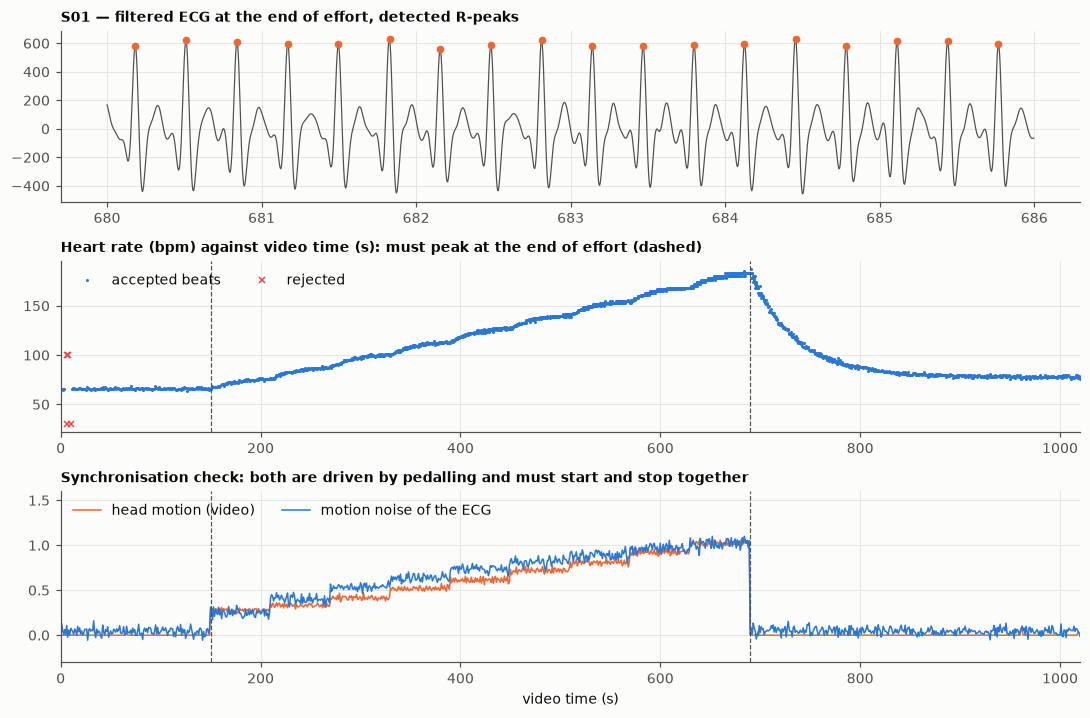

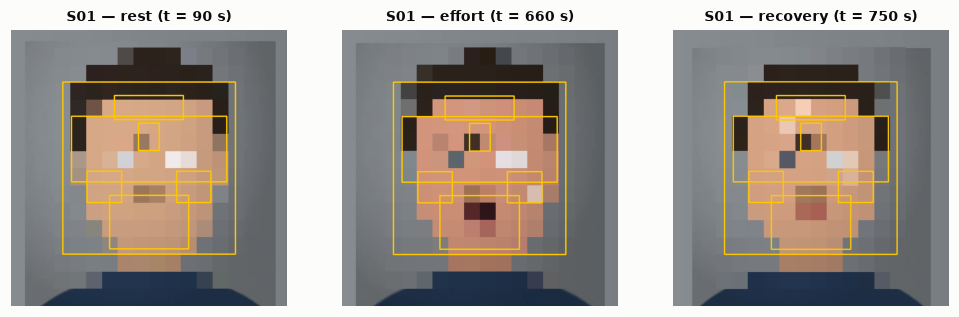

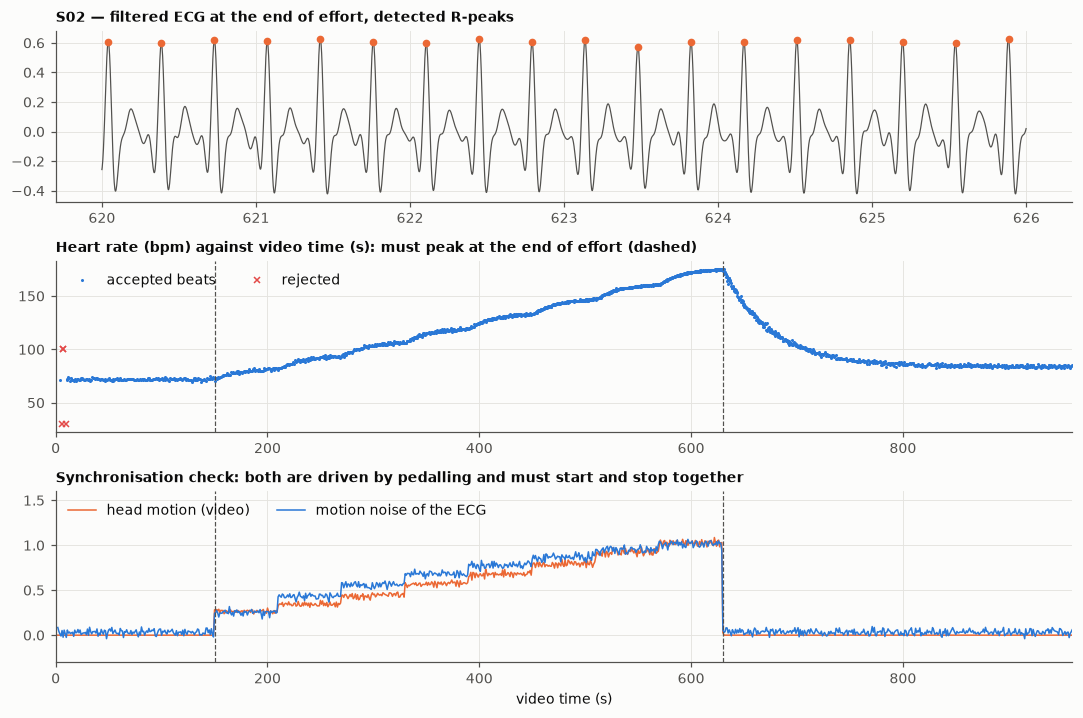

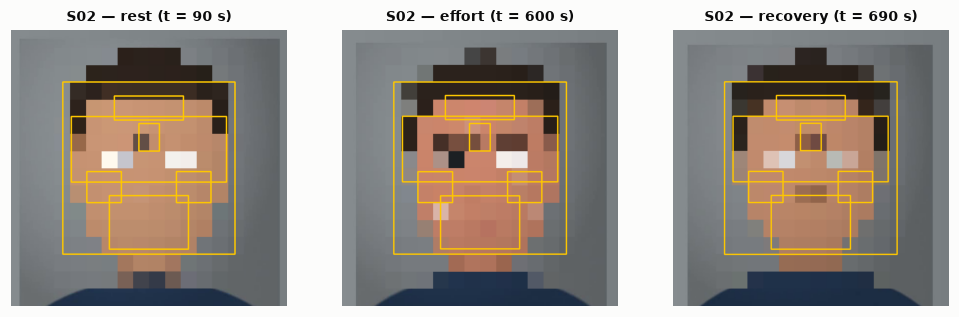

,session,condition,frames,detection_rate,box_available,sharp_ok,forehead_skin,eye_aspect_mean,eye_aspect_sd
0,S01,rest,3600,1.0,1.0,1.0,1.000,1.0,0.0
1,S01,effort,1800,1.0,1.0,1.0,0.999,1.0,0.0
2,S01,recovery,3600,1.0,1.0,1.0,0.998,1.0,0.0
3,S02,rest,3000,1.0,1.0,1.0,1.000,1.0,0.0
4,S02,effort,1500,1.0,1.0,1.0,0.999,1.0,0.0
5,S02,recovery,3000,1.0,1.0,1.0,0.995,1.0,0.0


Eye-box h/w: SD = 0.0000 over all frames -> constant by construction (fixed-aspect Haar window).


In [5]:
def label_seconds(sec, seg, p):
    """Segment labels and analysis windows for an array of integer seconds of video time."""
    out = pd.DataFrame(dict(segment=None, condition=None, stage=np.nan, power_W=np.nan, borg_cr10=np.nan,
                            window=None, stage_window=False), index=sec)
    for s in seg.itertuples():
        m = (sec >= s.t_start_s) & (sec < s.t_end_s)
        out.loc[m, ["segment", "condition"]] = s.segment, s.condition
        out.loc[m, ["stage", "power_W", "borg_cr10"]] = s.stage, s.power_W, s.borg_cr10
        if s.condition == "effort" and s.t_end_s - s.t_start_s >= p["min_stage_s"]:   # last 30 s, within the stage
            out.loc[m & (sec >= s.t_end_s - p["stage_window_s"]), "stage_window"] = True
    t_rest, t_end = seg[seg.condition == "rest"].t_end_s.max(), seg[seg.condition == "effort"].t_end_s.max()
    out.loc[(sec >= t_rest - p["rest_window_s"]) & (sec < t_rest) & (out.condition == "rest").values, "window"] = "rest"
    out.loc[(sec >= t_end - p["effort_window_s"]) & (sec < t_end), "window"] = "effort"
    out.loc[(sec >= t_end) & (sec < t_end + p["recovery_window_s"]), "window"] = "recovery"
    out.loc[(out.window == "rest").values, "stage_window"] = True  # rest = stage 0 of the dose-response
    out["t_since_end"] = sec - t_end
    return out


def sharp_floor(fr, win, p):
    """Sharpness below which a frame counts as blurred: a fraction of the median at rest (else recovery, else all)."""
    for m in (win == "rest", win == "recovery", np.ones(len(fr), bool)):
        if np.isfinite(fr.sharpness[m].median()):
            return p["sharp_rel_min"] * fr.sharpness[m].median()


def plot_ecg(sid):
    if ECG[sid] is None:
        return
    E, seg = ECG[sid], segments[segments.session_id == sid]
    t_end = seg[seg.condition == "effort"].t_end_s.max()
    fig, ax = plt.subplots(3, 1, figsize=(10, 6.6))
    m = (E["t"] >= t_end - 10) & (E["t"] < t_end - 4)
    r = E["r"][m[E["r"]]]
    ax[0].plot(E["t"][m], E["y"][m], color=INK2, lw=0.8)
    ax[0].plot(E["t"][r], E["y"][r], "o", ms=4, color=SERIES[1])
    ax[0].set_title(f"{sid} — filtered ECG at the end of effort, detected R-peaks", loc="left")
    rr = E["rr"]
    ax[1].plot(rr.t[rr.ok], 60 / rr.rr[rr.ok], ".", ms=2, color=SERIES[0], label="accepted beats")
    ax[1].plot(rr.t[~rr.ok], (60 / rr.rr[~rr.ok]).clip(30, 230), "x", ms=4, color=SERIES[7], label="rejected")
    ax[1].set_title("Heart rate (bpm) against video time (s): must peak at the end of effort (dashed)", loc="left")
    ax[1].legend(loc="upper left", ncol=2)
    unit = lambda v: (v - np.nanpercentile(v, 5)) / (np.nanpercentile(v, 95) - np.nanpercentile(v, 5) + 1e-12)
    ax[2].plot(E["motion"].index, unit(E["motion"]), color=SERIES[1], lw=1, label="head motion (video)")
    ax[2].plot(E["noise"].index, unit(E["noise"]), color=SERIES[0], lw=1, label="motion noise of the ECG")
    ax[2].set(ylim=(-0.3, 1.6), xlabel="video time (s)")
    ax[2].set_title("Synchronisation check: both are driven by pedalling and must start and stop together", loc="left")
    ax[2].legend(loc="upper left", ncol=2)
    for a in ax[1:]:
        a.set_xlim(0, FRAMES[sid].t_s.max())
        for x in (seg[seg.condition == "effort"].t_start_s.min(), t_end):
            a.axvline(x, color=INK2, lw=0.8, ls="--")
    fig.tight_layout()
    show(fig, f"ecg_qc_{sid}.png")


def plot_rois(sid):
    fr = FRAMES[sid]
    lab = label_seconds(np.arange(int(fr.t_s.max()) + 1), segments[segments.session_id == sid], PARAMS)
    cap = cv2.VideoCapture(os.path.join(DATA_DIR, sessions.loc[sid, "video_path"]))
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
    for ax, c in zip(axes, COND):
        ax.axis("off")
        secs = lab.index[lab.window == c]
        row = fr.iloc[(fr.t_s - secs[len(secs) // 2]).abs().argmin()] if len(secs) else None
        if row is None or not np.isfinite(row.box_w):
            continue
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(row.frame))
        img, box = turn(cap.read()[1], ROTATE[sid]).copy(), (row.box_x, row.box_y, row.box_w, row.box_h)
        if ANONYMIZE_FIGURES:                                      # pixelate the face before drawing the ROIs
            face = roi(img, box, (-0.05, -0.2, 1.05, 1.2))
            face[:] = cv2.resize(cv2.resize(face, (12, 14)), face.shape[1::-1], interpolation=cv2.INTER_NEAREST)
        x, y, w, h = box
        for fx0, fy0, fx1, fy1 in [(0, 0, 1, 1)] + list(PARAMS["roi"].values()):
            cv2.rectangle(img, (int(x + fx0 * w), int(y + fy0 * h)), (int(x + fx1 * w), int(y + fy1 * h)), (0, 200, 255), 2)
        ax.imshow(cv2.cvtColor(roi(img, box, (-0.3, -0.3, 1.3, 1.3)), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{sid} — {c} (t = {row.t_s:.0f} s)")
    cap.release()
    show(fig, f"roi_check_{sid}.png")


qc = []
for sid, fr in FRAMES.items():
    plot_ecg(sid)
    plot_rois(sid)
    win = label_seconds(np.floor(fr.t_s).astype(int).values, segments[segments.session_id == sid], PARAMS).window.values
    sharp_min = sharp_floor(fr, win, PARAMS)
    for c in COND:
        g = fr[win == c]
        qc.append(dict(session=sid, condition=c, frames=len(g), detection_rate=g.det.mean(),
                       box_available=g.box_w.notna().mean(), sharp_ok=(g.sharpness >= sharp_min).mean(),
                       forehead_skin=g.skin_frac.mean(), eye_aspect_mean=g.eye_aspect.mean(), eye_aspect_sd=g.eye_aspect.std()))
QC = pd.DataFrame(qc)
QC.to_csv(os.path.join(TAB_DIR, "quality_control.csv"), index=False)
display(QC.round(3))
print("Eye-box h/w: SD = %.4f over all frames -> constant by construction (fixed-aspect Haar window)."
      % pd.concat(FRAMES).eye_aspect.std())

## 6. Per-second features → `features.csv`
Per-frame features are aggregated per second (mean, SD, min, max in `features_second_stats.csv`; the mean in
`features.csv`, **one row per second, one column per feature**, with labels). Added per second:
`head_jitter` = SD of the raw box centre (% face width; its resting value is the detector's noise floor);
`mouth_open_pct` = share of frames with the mouth open (area ≥ 0.3 % of the face), the time-based score of Timme &
Brand (2020); `br_mouth` = spectral peak (0.15–1.2 Hz) of the mouth-area signal over 20 s, only when the mouth is
open and the peak is ≥ 3 × the median band power — keep the cadence ≥ 75 rpm so that pedalling stays above this
band; `blink_rate` = runs of 60–500 ms without any eye detected while the face is detected and
sharp, over a 30-s window. The glabella gradient is kept on sharp frames only. For the masked test, lower-face
features are set to missing.

In [6]:
def breathing_rate(fr, p, fs=10.0):
    """Breathing rate (breaths/min) per second from the mouth-area signal."""
    t, v = fr.t_s.values, fr.mouth_area.values.astype(float)
    ok, out = np.isfinite(v), {}
    if ok.sum() < 100:
        return pd.Series(out, name="br_mouth", dtype=float)
    grid = np.arange(t[0], t[-1], 1 / fs)
    x, valid = np.interp(grid, t[ok], v[ok]), np.interp(grid, t, ok.astype(float))
    n, f = int(p["br_win_s"] * fs), np.fft.rfftfreq(4096, 1 / fs)
    band = (f >= p["br_band_hz"][0]) & (f <= p["br_band_hz"][1])
    for i0 in range(0, len(x) - n, int(fs)):
        w = x[i0:i0 + n]
        if w.mean() < p["br_min_area"] or valid[i0:i0 + n].mean() < 0.8:
            continue
        P = np.abs(np.fft.rfft(signal.detrend(w) * np.hanning(n), 4096)) ** 2
        k = np.argmax(np.where(band, P, 0))
        if P[k] >= p["br_peak_ratio"] * np.median(P[band]):
            out[int(grid[i0 + n // 2])] = 60 * f[k]
    return pd.Series(out, name="br_mouth", dtype=float)


def blink_times(fr, sharp_min, p):
    """Onset times of blinks: short runs without any eye detected, flanked by frames with a sharp, detected face."""
    closed, good, t = (fr.eyes_n.fillna(0) == 0).values, (fr.det & (fr.sharpness >= sharp_min)).values, fr.t_s.values
    edges = np.flatnonzero(np.diff(closed.astype(int)))            # i such that closed[i] != closed[i + 1]
    starts, ends = edges[closed[edges + 1]] + 1, edges[~closed[edges + 1]] + 1
    ends = ends[ends > starts[0]] if len(starts) else ends
    return np.array([t[a] for a, b in zip(starts, ends)
                     if p["blink_dur_s"][0] <= t[b] - t[a] <= p["blink_dur_s"][1] and good[a - 1:b + 1].all()])


def aggregate(sid):
    fr, r, seg = FRAMES[sid].copy(), sessions.loc[sid], segments[segments.session_id == sid]
    fr["sec"] = np.floor(fr.t_s).astype(int)
    sharp_min = sharp_floor(fr, label_seconds(fr.sec.values, seg, PARAMS).window.values, PARAMS)
    fr.loc[fr.sharpness < sharp_min, "glabella_grad"] = np.nan
    g = fr.groupby("sec")
    stats4 = g[[f for f in FEATURES if f in fr] + ["eyes_n", "sharpness", "skin_frac"]].agg(["mean", "std", "min", "max"])
    out = stats4.xs("mean", axis=1, level=1).copy()
    out["head_jitter"] = 100 * np.hypot(g.raw_cx.std(), g.raw_cy.std()) / g.box_w.median()
    out["mouth_open_pct"] = 100 * g.mouth_area.agg(lambda v: (v.dropna() >= PARAMS["br_min_area"]).mean())
    out["det_rate"], out["n_frames"] = g.det.mean(), g.size()
    out = out.join(breathing_rate(fr, PARAMS)).join(ECG[sid]["hr"] if ECG[sid] else pd.Series(name="hr_ecg", dtype=float))
    bl, w = blink_times(fr, sharp_min, PARAMS), PARAMS["blink_win_s"]
    out["blink_rate"] = [((bl >= s + 0.5 - w / 2) & (bl < s + 0.5 + w / 2)).sum() * 60 / w for s in out.index]
    seen = (out.eyes_n > 0.5).rolling(w, center=True, min_periods=1).mean()     # share of seconds with eyes detected
    out.loc[seen < 0.5, "blink_rate"] = np.nan                     # eyes not visible (e.g. behind the mask): no count
    if int(opt(r, "mask", 0)):                                     # lower face hidden by the gas-exchange mask
        out[[f for f in FEATURES if not FEATURE_INFO[f][3]]] = np.nan
    out = pd.concat([label_seconds(out.index.values, seg, PARAMS), out], axis=1)
    out.insert(0, "t_s", out.index)
    stats4.columns = ["__".join(c) for c in stats4.columns]
    return out.assign(session_id=sid, subject_id=r.subject_id), stats4.reset_index().assign(session_id=sid)


parts = [aggregate(sid) for sid in sessions.index]
SEC = pd.concat([a for a, _ in parts], ignore_index=True)
SEC["hr_pct_max"] = 100 * SEC.hr_ecg / SEC.groupby("subject_id").hr_ecg.transform(
    lambda h: h.rolling(5, center=True, min_periods=3).mean().max())      # measured maximum (maximal tests)
COLS = (["session_id", "subject_id", "t_s", "segment", "condition", "stage", "power_W", "borg_cr10", "window",
         "stage_window", "t_since_end", "hr_ecg", "hr_pct_max"] + FEATURES + ["eyes_n", "sharpness", "skin_frac",
                                                                              "det_rate", "n_frames"])
SEC[COLS].to_csv(os.path.join(OUT_DIR, "features.csv"), index=False, float_format="%.5g")
pd.concat([b for _, b in parts]).to_csv(os.path.join(OUT_DIR, "features_second_stats.csv"), index=False, float_format="%.5g")
print(SEC.shape, "-> features.csv")

(1980, 32) -> features.csv


## 7. Descriptive statistics and time course
Mean, SD, minimum and maximum of each feature over the per-second values of each analysis window; time course of
every feature (thin line: 1-s values; thick line: 10-s moving mean); box plots per condition.

session_id        S01                     S02                 
window           rest  effort recovery   rest  effort recovery
feature                                                       
mouth_area        NaN     NaN      NaN   0.00    1.13     0.32
forehead_a      12.38   18.82    14.24  14.83   21.25    16.43
head_jitter      0.79    1.48     0.75   0.98    1.63     0.99
br_mouth          NaN     NaN      NaN    NaN   42.88    33.98
mouth_open_pct    NaN     NaN      NaN   0.00   90.27    36.77
cheek_a           NaN     NaN      NaN  14.49   21.57    16.73
cheek_hue         NaN     NaN      NaN  23.08   16.56    20.74
cheek_sat         NaN     NaN      NaN  42.57   44.91    42.58
cheek_val         NaN     NaN      NaN  73.30   76.41    74.45
shine_frac       0.00    1.78     3.38   0.00    1.21     1.53
glabella_grad    0.08    0.15     0.09   0.07    0.14     0.09
flow_rigid       0.01   18.72     0.03   0.01   19.91     0.01
flow_nonrigid    0.91    4.90     0.67   0.71    5.91     0.51
blink_rate       8.70   14.63     9.75  10.03   20.93    14.30
hr_ecg          66.05  178.66   115.06  72.04  170.70   116.07

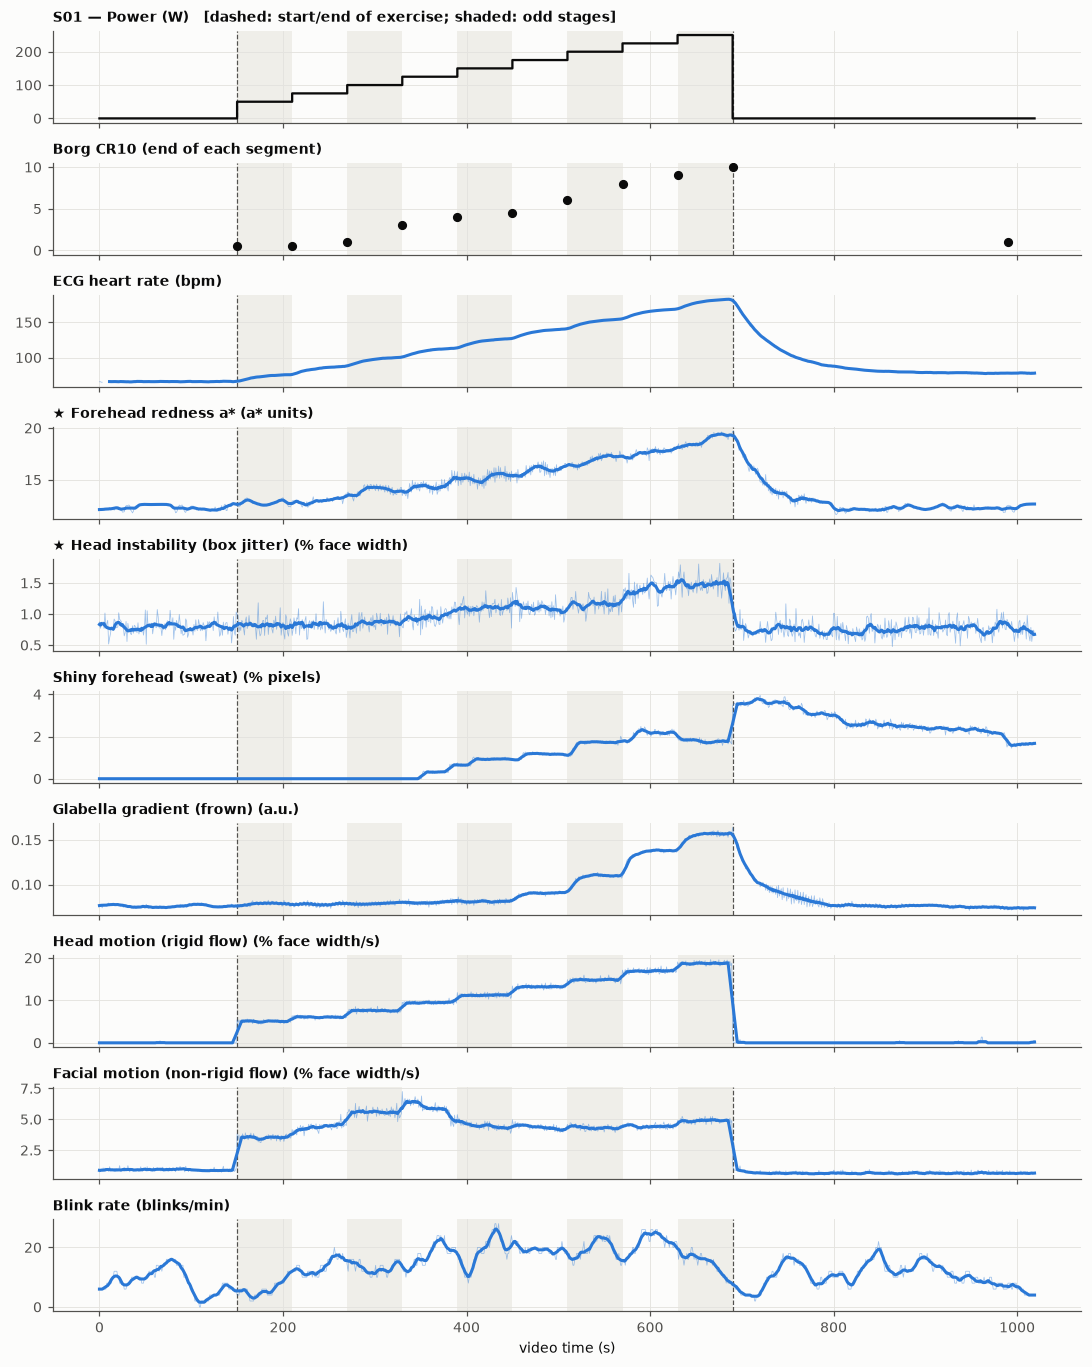

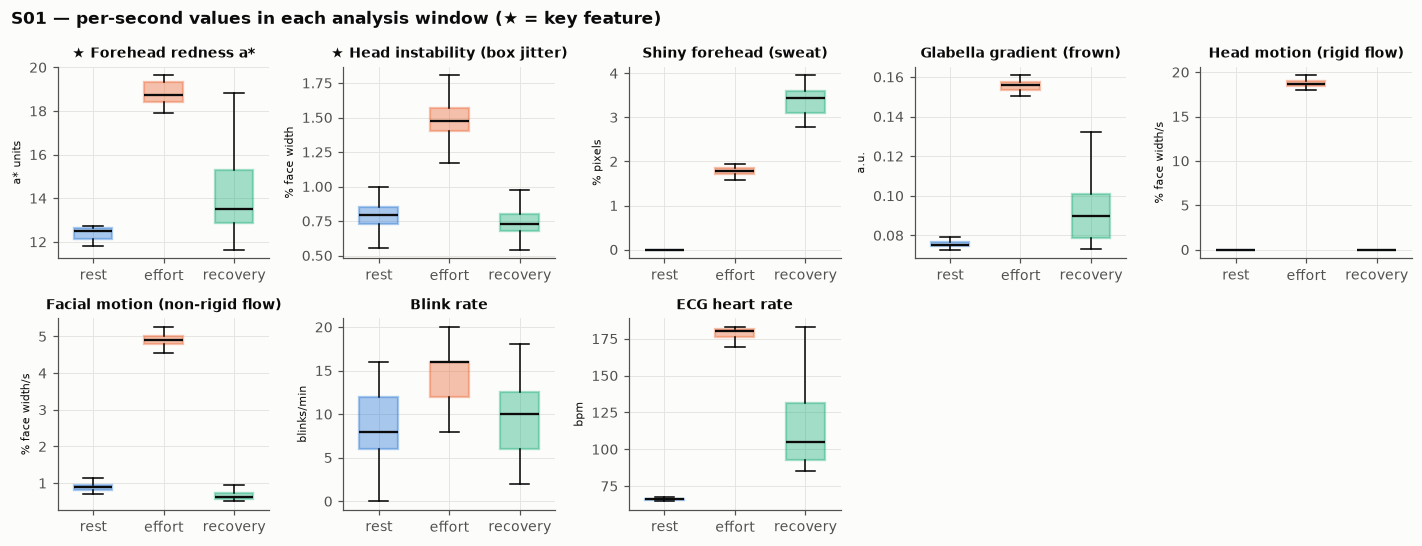

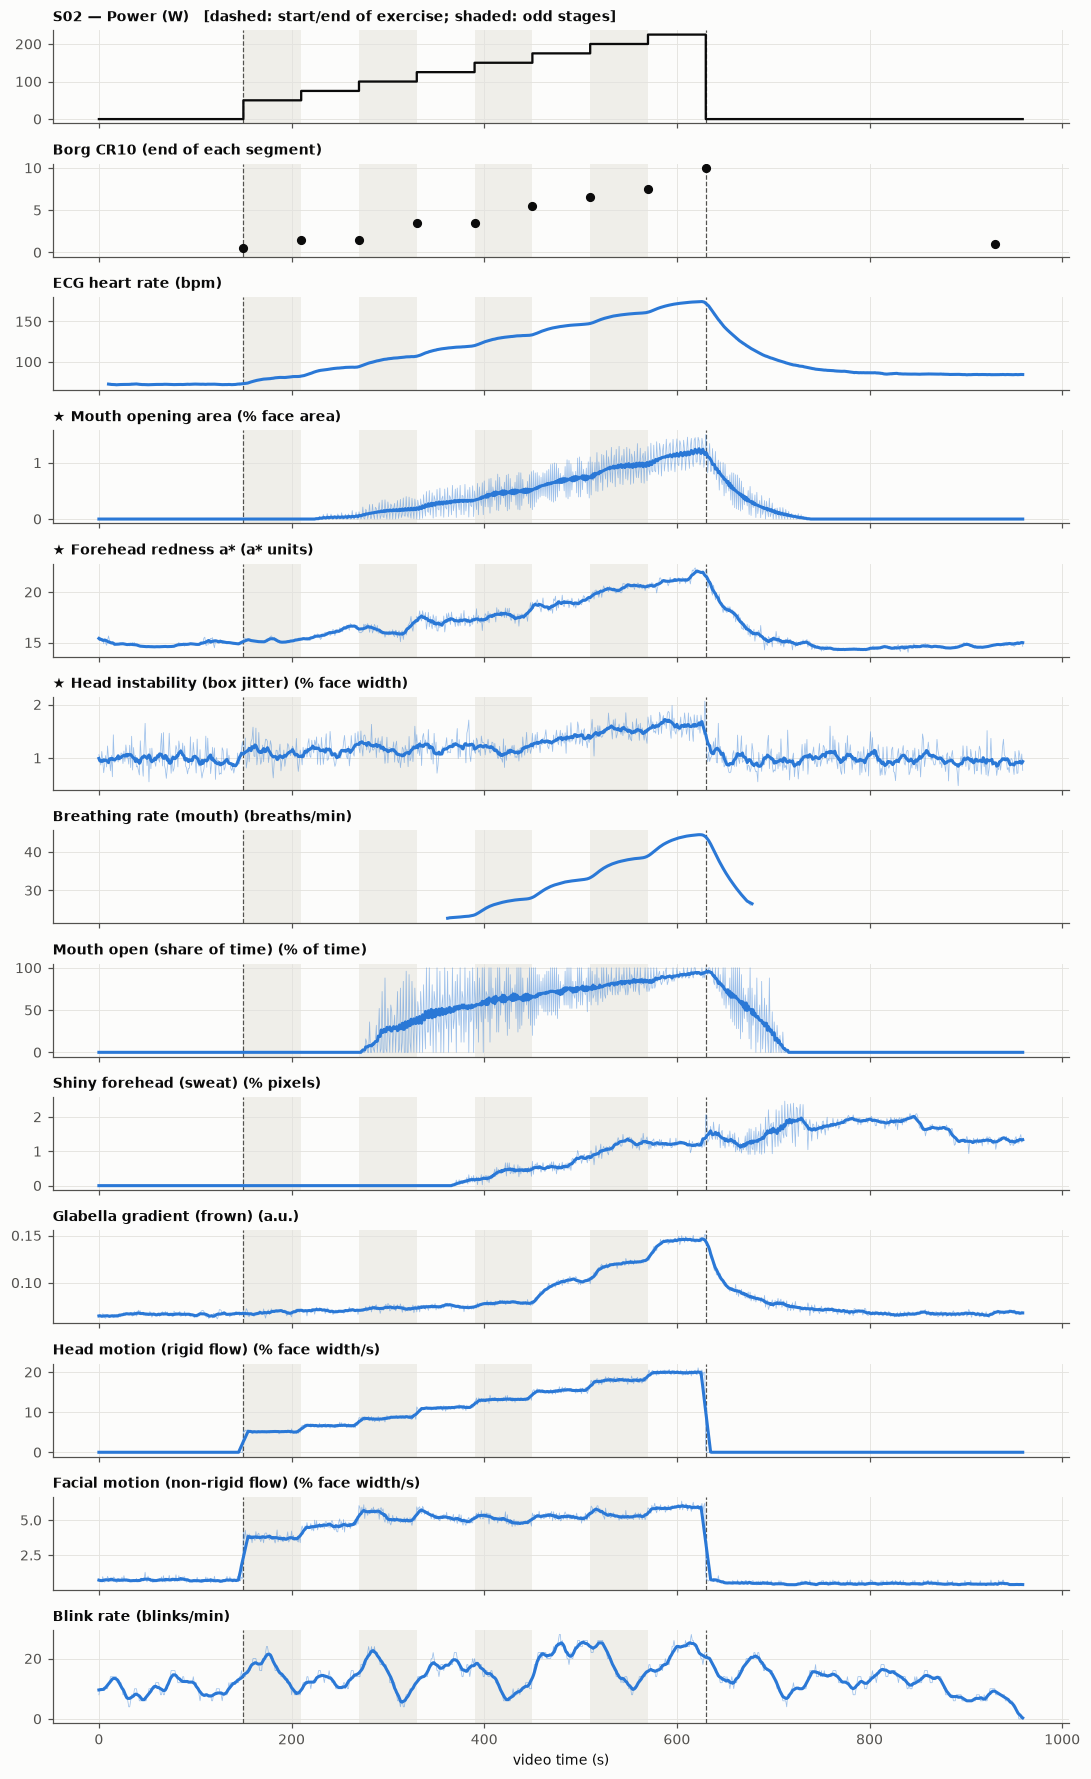

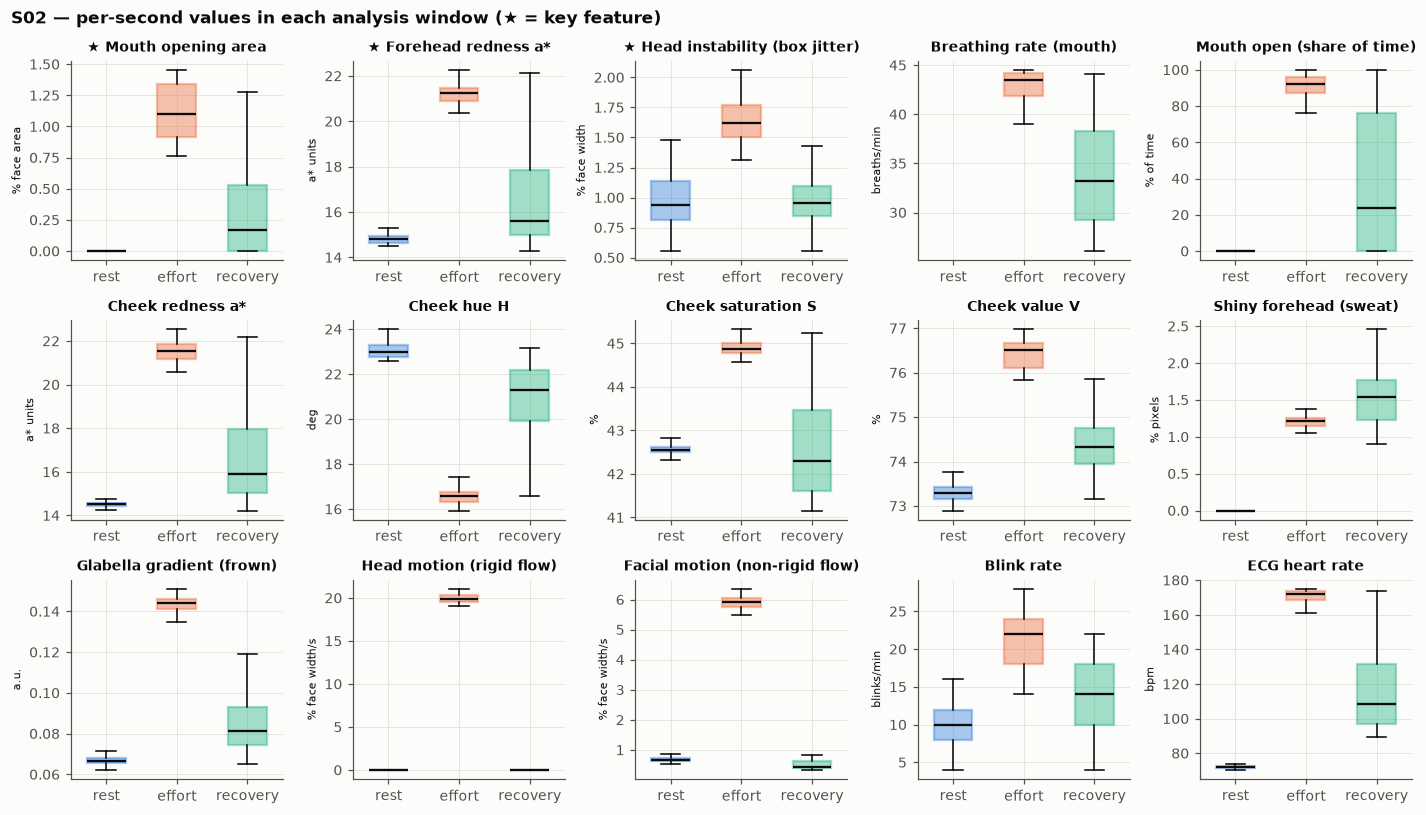

In [7]:
DESC = (SEC.dropna(subset=["window"]).melt(["session_id", "window"], ALL, "feature")
        .groupby(["session_id", "feature", "window"]).value.agg(["count", "mean", "std", "min", "max"]).reset_index())
DESC.to_csv(os.path.join(TAB_DIR, "descriptives.csv"), index=False)
display(DESC.pivot_table(index="feature", columns=["session_id", "window"], values="mean")
        .reindex(columns=list(COND), level=1).reindex(ALL).round(2))


def plot_timeline(sid):
    d, seg = SEC[SEC.session_id == sid].set_index("t_s"), segments[segments.session_id == sid]
    feats = ["hr_ecg"] + [f for f in FEATURES if not f.startswith("cheek_") and d[f].notna().any()]
    fig, axes = plt.subplots(len(feats) + 2, 1, figsize=(10, 1.25 * (len(feats) + 2)), sharex=True)
    eff = seg[seg.condition == "effort"]
    for ax in axes:
        for s in eff[eff.stage % 2 == 1].itertuples():
            ax.axvspan(s.t_start_s, s.t_end_s, color="#efeee9", lw=0)
        for x in (eff.t_start_s.min(), eff.t_end_s.max()):
            ax.axvline(x, color=INK2, lw=0.8, ls="--")
    axes[0].step(d.index, d.power_W.fillna(0), where="post", color=INK)
    axes[0].set_title(f"{sid} — Power (W)   [dashed: start/end of exercise; shaded: odd stages]", loc="left")
    axes[1].plot(seg.t_end_s, seg.borg_cr10, "o", ms=5, color=INK)
    axes[1].set(ylim=(-0.5, 10.5))
    axes[1].set_title("Borg CR10 (end of each segment)", loc="left")
    for ax, f in zip(axes[2:], feats):
        ax.plot(d.index, d[f], color=SERIES[0], lw=0.5, alpha=0.45)
        ax.plot(d.index, d[f].rolling(10, center=True, min_periods=5).mean(), color=SERIES[0], lw=2)
        ax.set_title(f"{label(f)} ({FEATURE_INFO[f][1]})", loc="left")
    axes[-1].set_xlabel("video time (s)")
    fig.tight_layout()
    show(fig, f"timeline_{sid}.png")


def plot_boxes(sid):
    d = SEC[(SEC.session_id == sid) & SEC.window.notna()]
    feats = [f for f in ALL if d[f].notna().any()]
    nrow = int(np.ceil(len(feats) / 5))
    fig, axes = plt.subplots(nrow, 5, figsize=(13, 2.5 * nrow), squeeze=False)
    for ax in axes.flat[len(feats):]:
        ax.axis("off")
    for ax, f in zip(axes.flat, feats):
        bp = ax.boxplot([d.loc[d.window == c, f].dropna().values for c in COND], widths=0.55, patch_artist=True,
                        showfliers=False, medianprops=dict(color=INK, lw=1.5))
        for patch, c in zip(bp["boxes"], COND.values()):
            patch.set(facecolor=c, alpha=0.4, edgecolor=c, lw=1.5)
        ax.set_xticks([1, 2, 3], list(COND))
        ax.set_title(label(f))
        ax.set_ylabel(FEATURE_INFO[f][1], fontsize=7.5)
    fig.suptitle(f"{sid} — per-second values in each analysis window (★ = key feature)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    show(fig, f"boxplots_{sid}.png")


for sid in sessions.index:
    plot_timeline(sid)
    plot_boxes(sid)

## 8. Rest vs effort vs recovery
Each video contains one subject: inference is **within one test**. Consecutive seconds are strongly autocorrelated
(treating them as independent would be pseudo-replication) and pairing second *i* of rest with second *i* of effort
is arbitrary. Per-second values are therefore averaged into **non-overlapping 10-s blocks** (≥ 7 valid seconds),
the lag-1 autocorrelation of block residuals is checked, and blocks are compared with rank tests —
**Kruskal–Wallis** across the three conditions, **Mann–Whitney U** for each pair (Holm) — with **effect sizes and
95 % bootstrap CIs** (blocks resampled, fixed seed): Cliff's δ (−1 to +1), Hedges' g and the mean difference in the
feature's unit. A paired test is used where pairing is real: between the two tests at matched stages (§10).

,session,feature,family,n_blocks,diff,diff_lo,diff_hi,cliff_delta,delta_lo,delta_hi,hedges_g,kw_p,lag1_acf,mwu_p_holm,kw_p_holm
0,S01,forehead_a,key,6/12,6.440,6.039,6.829,1.000,1.000,1.0,18.192,0.000,0.699,0.000,0.000
3,S01,head_jitter,key,6/12,0.692,0.653,0.731,1.000,1.000,1.0,15.288,0.000,-0.062,0.000,0.000
6,S01,shine_frac,exploratory,6/12,1.785,1.749,1.823,1.000,1.000,1.0,58.573,0.000,0.865,0.000,0.000
9,S01,glabella_grad,exploratory,6/12,0.079,0.075,0.082,1.000,1.000,1.0,27.081,0.000,0.615,0.000,0.000
12,S01,flow_rigid,exploratory,6/12,18.713,18.623,18.786,1.000,1.000,1.0,279.465,0.000,-0.101,0.000,0.000
15,S01,flow_nonrigid,exploratory,6/12,3.988,3.938,4.027,1.000,1.000,1.0,83.712,0.000,0.350,0.000,0.000
18,S01,blink_rate,exploratory,6/12,5.933,2.433,9.267,0.722,0.278,1.0,1.364,0.029,0.739,0.040,0.029
21,S01,hr_ecg,reference,6/12,112.614,109.460,115.492,1.000,1.000,1.0,44.951,0.000,0.758,0.000,0.000
24,S02,mouth_area,key,6/12,1.128,1.083,1.174,1.000,1.000,1.0,30.466,0.000,0.739,0.000,0.000
27,S02,forehead_a,key,6/12,6.422,6.078,6.781,1.000,1.000,1.0,19.894,0.000,0.740,0.000,0.000


Median lag-1 autocorrelation of block residuals: 0.72 (> 0.3: blocks are not independent, read the p-values with caution)


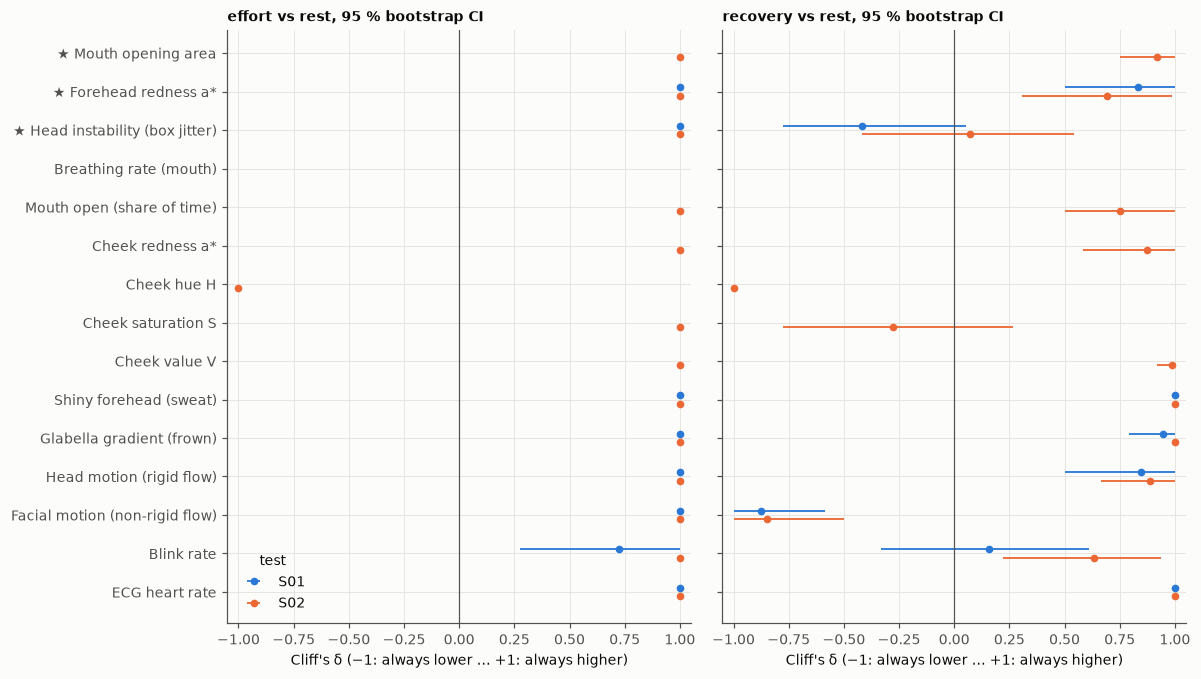

In [8]:
def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    out = np.empty(len(p))
    out[order] = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    return out


def blocks(d, f, p):
    """Means of non-overlapping 10-s blocks of feature f in one window."""
    g = d.groupby((d.t_s - d.t_s.min()) // p["block_s"])[f]
    return g.mean()[g.count() >= p["min_valid_s"]].values


def cliffs_delta(b, a):
    return np.sign(b[:, None] - a[None, :]).mean()


def hedges_g(b, a):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (b.mean() - a.mean()) / sp * (1 - 3 / (4 * (na + nb) - 9)) if sp > 0 else np.nan


def compare_conditions(SEC, feats, p):
    rows, rng = [], np.random.default_rng(SEED)
    for sid, d in SEC.groupby("session_id"):
        for f in feats:
            B = {c: b for c, b in ((c, blocks(d[d.window == c], f, p)) for c in COND) if len(b) >= 2}
            if len(B) < 2:                                         # e.g. a video without rest: the other pair is kept
                continue
            res = np.concatenate([b - b.mean() for b in B.values()])
            try:
                kw_p = stats.kruskal(*B.values()).pvalue
            except ValueError:                                     # all values identical
                kw_p = np.nan
            for c1, c0 in (("effort", "rest"), ("recovery", "rest"), ("recovery", "effort")):
                if c1 not in B or c0 not in B:
                    continue
                b, a = B[c1], B[c0]
                boot = np.array([(bb.mean() - aa.mean(), cliffs_delta(bb, aa)) for bb, aa in
                                 ((rng.choice(b, len(b)), rng.choice(a, len(a))) for _ in range(p["n_boot"]))])
                (d_lo, c_lo), (d_hi, c_hi) = np.percentile(boot, [2.5, 97.5], axis=0)
                rows.append(dict(session=sid, feature=f, family=FEATURE_INFO[f][2], contrast=f"{c1} vs {c0}",
                                 n_blocks=f"{len(b)}/{len(a)}", mean_1=b.mean(), mean_0=a.mean(), diff=b.mean() - a.mean(),
                                 diff_lo=d_lo, diff_hi=d_hi, cliff_delta=cliffs_delta(b, a), delta_lo=c_lo, delta_hi=c_hi,
                                 hedges_g=hedges_g(b, a), kw_p=kw_p, mwu_p=stats.mannwhitneyu(b, a).pvalue,
                                 lag1_acf=np.corrcoef(res[1:], res[:-1])[0, 1]))
    out = pd.DataFrame(rows)
    out["mwu_p_holm"] = out.groupby(["session", "feature"]).mwu_p.transform(holm)        # 3 pairs per feature
    kw = out.drop_duplicates(["session", "feature"]).copy()
    kw["kw_p_holm"] = kw.groupby(["session", "family"]).kw_p.transform(lambda q: holm(q.fillna(1)))   # within family
    return out.merge(kw[["session", "feature", "kw_p_holm"]])


COMP = compare_conditions(SEC, ALL, PARAMS)
COMP.to_csv(os.path.join(TAB_DIR, "comparisons.csv"), index=False)
display(COMP[COMP.contrast == "effort vs rest"].drop(columns=["contrast", "mean_0", "mean_1", "mwu_p"]).round(3))
print("Median lag-1 autocorrelation of block residuals:", round(COMP.lag1_acf.median(), 2),
      "(> 0.3: blocks are not independent, read the p-values with caution)")

fig, axes = plt.subplots(1, 2, figsize=(11, 0.33 * len(ALL) + 1.3), sharey=True)
for ax, ct in zip(axes, ("effort vs rest", "recovery vs rest")):
    for k, sid in enumerate(sessions.index):
        d = COMP[(COMP.contrast == ct) & (COMP.session == sid)].set_index("feature").reindex(ALL)
        err = np.nan_to_num(np.clip([d.cliff_delta - d.delta_lo, d.delta_hi - d.cliff_delta], 0, None))
        ax.errorbar(d.cliff_delta, np.arange(len(ALL)) + 0.22 * (k - 0.5), xerr=err, fmt="o", ms=4, color=SERIES[k],
                    elinewidth=1.2, label=sid)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set(xlim=(-1.05, 1.05), xlabel="Cliff's δ (−1: always lower … +1: always higher)")
    ax.set_title(f"{ct}, 95 % bootstrap CI", loc="left")
axes[0].set_yticks(range(len(ALL)), [label(f) for f in ALL])
axes[0].invert_yaxis()
axes[0].legend(title="test", loc="lower left")
fig.tight_layout()
show(fig, "effect_sizes.png")

## 9. Dose–response, primary outcome and intensity domains
Each stage contributes one point: the mean of its **last 30 s** (rest = stage 0; an incomplete last stage counts if
it lasted ≥ 15 s). Within each test: Spearman's ρ, permutation p-value (9 999 permutations, fixed seed) and Fisher-z
CI (Bonett–Wright SE). When several tests have the feature, the **repeated-measures correlation** (rmcorr; Bakdash
& Marusich 2017, used by Timme & Brand 2020) gives the common within-test association; the clusters are the tests,
and two tests of the same participant are not independent subjects. Stages are assigned to the **moderate / heavy /
severe** domains with the powers at VT1 and VT2 of each participant (masked test).

In a ramp, intensity and time rise together: any feature that drifts will correlate with Borg. The domains, the
matched-stage comparison (§10) and the recovery (§12) are what separates exertion from mere elapsed time.

In [9]:
def spearman(x, y, n_perm, seed=SEED):
    """Spearman rho, permutation p-value, 95 % CI (Fisher z, Bonett-Wright SE), n."""
    ok = np.isfinite(x) & np.isfinite(y)
    x, y, n = stats.rankdata(x[ok]), stats.rankdata(y[ok]), int(ok.sum())
    if n < 5 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return dict(rho=np.nan, p=np.nan, lo=np.nan, hi=np.nan, n=n)

    def pearson(a, b, axis=-1):                                    # Spearman = Pearson on ranks
        a, b = a - a.mean(axis, keepdims=True), b - b.mean(axis, keepdims=True)
        return (a * b).sum(axis) / np.sqrt((a * a).sum(axis) * (b * b).sum(axis))

    rho = float(pearson(x, y))
    pv = stats.permutation_test((x, y), pearson, permutation_type="pairings", vectorized=True, n_resamples=n_perm,
                                random_state=seed).pvalue
    lo, hi = np.tanh(np.arctanh(np.clip(rho, -0.999, 0.999)) + np.array([-1.96, 1.96]) * np.sqrt((1 + rho ** 2 / 2) / (n - 3)))
    return dict(rho=rho, p=pv, lo=lo, hi=hi, n=n)


def rmcorr(d, x, y, cluster="session_id"):
    """Repeated-measures correlation: Pearson r of the within-cluster centred values, dof = N - k - 1."""
    d = d[[x, y, cluster]].dropna()
    d = d[d.groupby(cluster)[x].transform("count") >= 3]
    k, dof = d[cluster].nunique(), len(d) - d[cluster].nunique() - 1
    if k < 2 or dof < 3:
        return dict(rho=np.nan, p=np.nan, lo=np.nan, hi=np.nan, n=len(d))
    r = np.corrcoef(*(d[v] - d.groupby(cluster)[v].transform("mean") for v in (x, y)))[0, 1]
    lo, hi = np.tanh(np.arctanh(np.clip(r, -0.999, 0.999)) + np.array([-1.96, 1.96]) / np.sqrt(dof - 1))
    return dict(rho=r, p=2 * stats.t.sf(abs(r) * np.sqrt(dof / max(1e-12, 1 - r ** 2)), dof), lo=lo, hi=hi, n=len(d))


STAGES = (SEC[SEC.stage_window & (SEC.stage >= 0)].groupby(["subject_id", "session_id", "stage"])
          [ALL + ["hr_pct_max", "power_W", "borg_cr10"]].mean().reset_index())
if CPET is not None:
    STAGES = STAGES.merge(CPET, on=["subject_id", "stage"], how="left")
VT = sessions.reindex(columns=["vt1_W", "vt2_W"]).astype(float)
vt = VT.loc[STAGES.session_id].values
STAGES["domain"] = np.select([STAGES.stage == 0, STAGES.power_W < vt[:, 0], STAGES.power_W < vt[:, 1],
                              np.isfinite(vt[:, 1])], ["rest", "moderate", "heavy", "severe"], "n/a")
STAGES.to_csv(os.path.join(TAB_DIR, "stage_means.csv"), index=False)
REFS = ["borg_cr10", "hr_ecg", "power_W"] + [c for c in ("vo2", "ve", "bf") if c in STAGES]
DOSE = pd.DataFrame([dict(feature=f, reference=ref, level=lev, **res)
                     for f in ALL for ref in REFS if f != ref
                     for lev, res in [(sid, spearman(g[f].values, g[ref].values, PARAMS["n_perm"]))
                                      for sid, g in STAGES.groupby("session_id")] + [("rmcorr", rmcorr(STAGES, f, ref))]])
DOSE.to_csv(os.path.join(TAB_DIR, "dose_response.csv"), index=False)
display(DOSE.pivot_table(index="feature", columns=["reference", "level"], values="rho").reindex(ALL).round(2))
if (STAGES.domain != "n/a").any():
    DOMAINS = STAGES.groupby(["session_id", "domain"])[ALL + ["borg_cr10"]].mean().reindex(
        ["rest", "moderate", "heavy", "severe"], level=1)
    DOMAINS.to_csv(os.path.join(TAB_DIR, "intensity_domains.csv"))
    display(DOMAINS.round(2).T)

reference         bf              borg_cr10              hr_ecg              power_W                 ve                vo2             
level            S01   S02 rmcorr       S01   S02 rmcorr    S01   S02 rmcorr     S01   S02 rmcorr   S01   S02 rmcorr   S01   S02 rmcorr
feature                                                                                                                                
mouth_area       NaN  1.00    NaN       NaN  0.98    NaN    NaN  1.00    NaN     NaN  1.00    NaN   NaN  1.00    NaN   NaN  1.00    NaN
forehead_a      1.00  0.98   0.99      1.00  0.96   0.98   1.00  0.98   0.99    1.00  0.98   0.97  1.00  0.98   0.96  1.00  0.98   0.96
head_jitter     0.98  0.92   0.97      0.97  0.87   0.95   0.98  0.92   0.96    0.98  0.92   0.93  0.98  0.92   0.96  0.98  0.92   0.92
br_mouth         NaN  1.00    NaN       NaN  1.00    NaN    NaN  1.00    NaN     NaN  1.00    NaN   NaN  1.00    NaN   NaN  1.00    NaN
mouth_open_pct   NaN  0.98    NaN       NaN  0.98    NaN    NaN  0.98    NaN     NaN  0.98    NaN   NaN  0.98    NaN   NaN  0.98    NaN
cheek_a          NaN  1.00    NaN       NaN  0.99    NaN    NaN  1.00    NaN     NaN  1.00    NaN   NaN  1.00    NaN   NaN  1.00    NaN
cheek_hue        NaN -0.98    NaN       NaN -0.97    NaN    NaN -0.98    NaN     NaN -0.98    NaN   NaN -0.98    NaN   NaN -0.98    NaN
cheek_sat        NaN  0.92    NaN       NaN  0.91    NaN    NaN  0.92    NaN     NaN  0.92    NaN   NaN  0.92    NaN   NaN  0.92    NaN
cheek_val        NaN  0.95    NaN       NaN  0.94    NaN    NaN  0.95    NaN     NaN  0.95    NaN   NaN  0.95    NaN   NaN  0.95    NaN
shine_frac      0.96  0.94   0.95      0.96  0.93   0.93   0.96  0.94   0.93    0.96  0.94   0.89  0.96  0.94   0.89  0.96  0.94   0.88
glabella_grad   0.99  1.00   0.94      0.98  0.99   0.91   0.99  1.00   0.89    0.99  1.00   0.85  0.99  1.00   0.96  0.99  1.00   0.83
flow_rigid      1.00  1.00   0.95      1.00  0.99   0.96   1.00  1.00   0.98    1.00  1.00   0.99  1.00  1.00   0.91  1.00  1.00   0.99
flow_nonrigid   0.32  0.95   0.51      0.32  0.94   0.56   0.32  0.95   0.60    0.32  0.95   0.69  0.32  0.95   0.51  0.32  0.95   0.72
blink_rate      0.58  0.43   0.54      0.58  0.41   0.57   0.58  0.43   0.58    0.58  0.43   0.60  0.58  0.43   0.45  0.58  0.43   0.60
hr_ecg          1.00  1.00   0.99      1.00  0.99   0.99    NaN   NaN    NaN    1.00  1.00   0.99  1.00  1.00   0.95  1.00  1.00   0.98

session_id        S01                             S02                         
domain           rest moderate   heavy  severe   rest moderate   heavy  severe
mouth_area        NaN      NaN     NaN     NaN   0.00     0.07    0.50    1.07
forehead_a      12.38    13.33   15.35   18.12  14.83    15.91   17.99   21.06
head_jitter      0.79     0.84    1.06    1.36   0.98     1.10    1.25    1.56
br_mouth          NaN      NaN     NaN     NaN    NaN      NaN   27.74   41.18
mouth_open_pct    NaN      NaN     NaN     NaN   0.00    10.71   63.56   88.47
cheek_a           NaN      NaN     NaN     NaN  14.49    15.66   18.65   21.32
cheek_hue         NaN      NaN     NaN     NaN  23.08    22.36   19.40   16.84
cheek_sat         NaN      NaN     NaN     NaN  42.57    43.44   44.62   44.79
cheek_val         NaN      NaN     NaN     NaN  73.30    73.30   74.44   76.32
shine_frac       0.00     0.00    0.84    1.89   0.00     0.00    0.42    1.24
glabella_grad    0.08     0.08    0.08    0.13   0.07     0.07    0.09    0.13
flow_rigid       0.01     6.23   11.34   16.85   0.01     6.84   13.31   18.94
flow_nonrigid    0.91     4.54    4.72    4.54   0.71     4.44    5.03    5.60
blink_rate       8.70    12.20   20.64   18.71  10.03    11.38   16.67   17.93
hr_ecg          66.05    87.04  125.84  167.58  72.04    93.02  131.98  166.74
borg_cr10        0.50     1.50    4.83    9.00   0.50     2.17    5.17    8.75

### 9.1 Primary outcome: mouth-opening area vs Borg CR10 (test without mask)

,feature,reference,level,rho,p,lo,hi,n
1,mouth_area,borg_cr10,S02,0.983,0.0,0.887,0.998,9


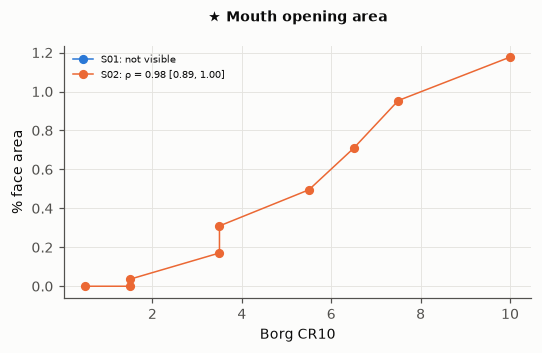

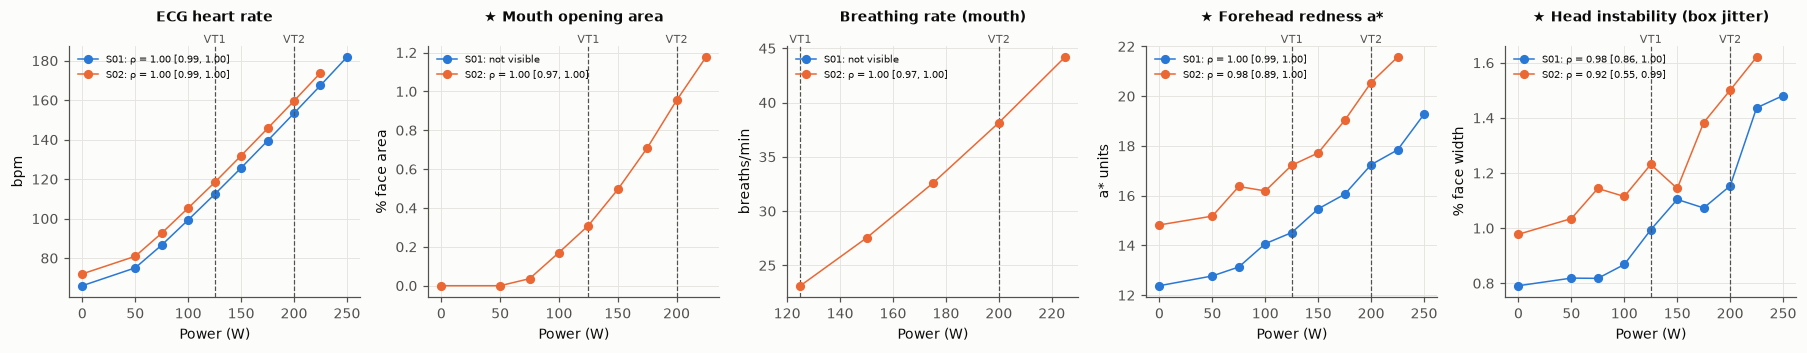

In [10]:
PRIM = DOSE[(DOSE.feature == "mouth_area") & (DOSE.reference == "borg_cr10")].dropna(subset=["rho"])
PRIM.to_csv(os.path.join(TAB_DIR, "primary_outcome.csv"), index=False)
display(PRIM.round(3))


def plot_dose(feats, ref, ref_label, name):
    """Stage means of each feature against a reference, one line per test; VT1 and VT2 marked on the power axis."""
    fig, axes = plt.subplots(1, len(feats), figsize=(max(5, 3.3 * len(feats)), 3.3), squeeze=False)
    subjects = sorted(sessions.subject_id.unique())
    rows = len(subjects) if ref == "power_W" else 1                # one row of threshold labels per subject
    for ax, f in zip(axes[0], feats):
        for k, (sid, g) in enumerate(STAGES.groupby("session_id")):
            r = DOSE[(DOSE.feature == f) & (DOSE.reference == ref) & (DOSE.level == sid)].iloc[0]
            txt = f"{sid}: ρ = {r.rho:.2f} [{r.lo:.2f}, {r.hi:.2f}]" if np.isfinite(r.rho) else f"{sid}: not visible"
            ax.plot(g[ref], g[f], "o-", ms=5, lw=1, color=SERIES[k], label=txt)
            subj, col = sessions.loc[sid, "subject_id"], INK2 if len(subjects) == 1 else SERIES[k]
            if ref != "power_W" or sid != sessions.index[sessions.subject_id == subj].min():
                continue                                           # thresholds drawn once per subject
            for v, name_v in zip(VT.loc[sid], ("VT1", "VT2")):
                if np.isfinite(v):
                    ax.axvline(v, color=col, ls="--", lw=0.8)
                    ax.annotate(name_v if len(subjects) == 1 else f"{name_v} {subj}",
                                (v, 1.0 + 0.055 * subjects.index(subj)), xycoords=("data", "axes fraction"),
                                ha="center", va="bottom", fontsize=7.5 if len(subjects) == 1 else 6, color=col)
        ax.set_title(label(f), y=1.06 + 0.055 * (rows - 1))
        ax.set(xlabel=ref_label, ylabel=FEATURE_INFO[f][1])
        ax.legend(fontsize=6.5, loc="best")
    fig.tight_layout()
    show(fig, name)


plot_dose(["mouth_area"], "borg_cr10", "Borg CR10", "primary_outcome.png")
plot_dose(["hr_ecg", "mouth_area", "br_mouth", "forehead_a", "head_jitter"], "power_W", "Power (W)", "dose_response_power.png")

## 10. Unmasked vs masked test at matched stages (upper face)
The two tests of a participant share the same stages, so each stage is a **matched pair**: same external load
[edit: order of the two tests and time between them]. For the features visible in both tests (upper face), heart
rate and Borg CR10: mean difference v2 − v1 with a bootstrap 95 % CI over stages, **Wilcoxon signed-rank test** and
matched-pairs rank-biserial correlation (effect size). A feature that shifts like heart rate and Borg CR10 at
equal power follows the internal state rather than the external load. The mask itself (weight, straps, heat) and
the order of the tests are confounded with this contrast.

,subject,contrast,feature,n_stages,mean_diff,lo,hi,wilcoxon_p,rank_biserial
0,A,S02 − S01,hr_ecg,9,6.104,6.008,6.201,0.004,1.000
1,A,S02 − S01,borg_cr10,9,0.389,0.000,0.778,0.125,0.622
2,A,S02 − S01,forehead_a,9,2.796,2.469,3.139,0.004,1.000
3,A,S02 − S01,head_jitter,9,0.233,0.173,0.286,0.004,1.000
4,A,S02 − S01,shine_frac,9,-0.301,-0.523,-0.104,0.062,-0.778
5,A,S02 − S01,glabella_grad,9,-0.001,-0.006,0.005,0.910,-0.067
6,A,S02 − S01,flow_rigid,9,1.536,0.838,2.247,0.008,0.956
7,A,S02 − S01,flow_nonrigid,9,0.328,-0.107,0.789,0.359,0.378
8,A,S02 − S01,blink_rate,9,-2.341,-6.335,1.230,0.496,-0.289


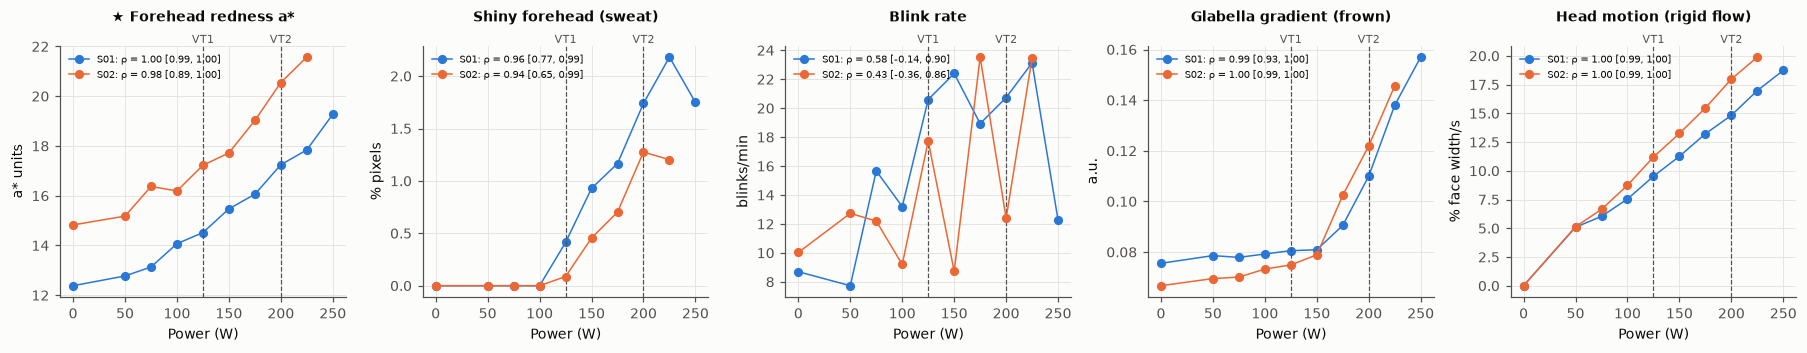

In [11]:
def matched_stages(STAGES, feats, n_boot):
    rows, rng = [], np.random.default_rng(SEED)
    for subj, g in STAGES.groupby("subject_id"):
        sids = list(g.session_id.unique())
        if len(sids) != 2:
            continue
        a, b = (g[g.session_id == s].set_index("stage") for s in sids)
        for f in feats:
            d = (b[f] - a[f]).dropna().values
            if len(d) < 5 or not d.any():
                continue
            rk = stats.rankdata(np.abs(d))
            lo, hi = np.percentile(rng.choice(d, (n_boot, len(d))).mean(1), [2.5, 97.5])
            rows.append(dict(subject=subj, contrast=f"{sids[1]} − {sids[0]}", feature=f, n_stages=len(d), mean_diff=d.mean(),
                             lo=lo, hi=hi, wilcoxon_p=stats.wilcoxon(d).pvalue,
                             rank_biserial=(rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum()))
    return pd.DataFrame(rows)


UPPER = ["hr_ecg", "borg_cr10"] + [f for f in FEATURES if FEATURE_INFO[f][3]]
MATCH = matched_stages(STAGES, UPPER, PARAMS["n_boot"])
if len(MATCH):
    MATCH.to_csv(os.path.join(TAB_DIR, "matched_stages.csv"), index=False)
    display(MATCH.round(3))
    plot_dose(["forehead_a", "shine_frac", "blink_rate", "glabella_grad", "flow_rigid"], "power_W", "Power (W)",
              "matched_stages.png")
else:
    print("Matched-stage comparison skipped: it needs two tests of the same subject.")

## 11. Correlations between features
Two features that both drift with time correlate even if they are unrelated. The Spearman matrix is therefore shown
on 10-s block means over the whole test, on **levels** and on **first differences** (block-to-block changes),
which removes the shared trend.

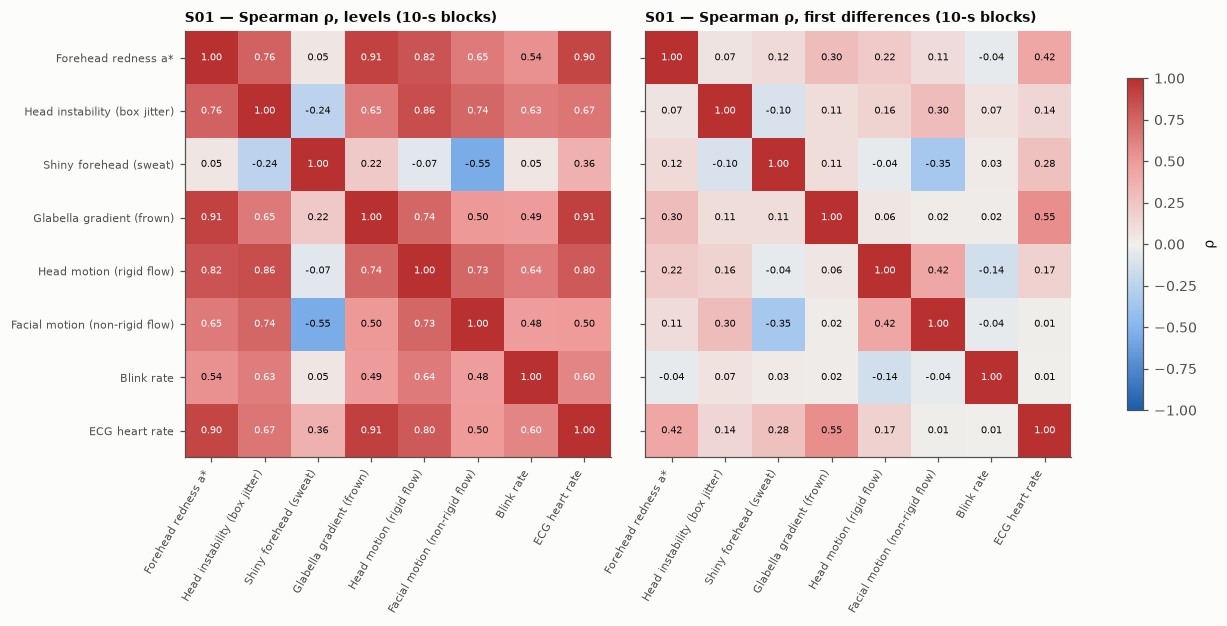

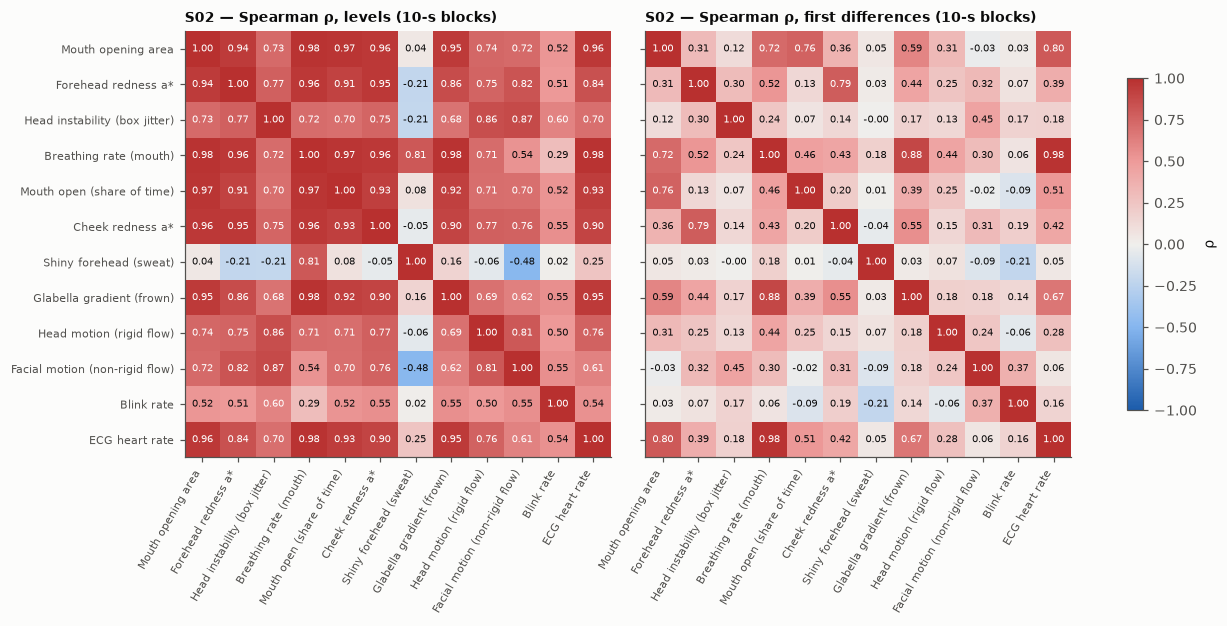

In [12]:
def plot_corr(sid):
    d = SEC[(SEC.session_id == sid) & SEC.condition.notna()]
    feats = [f for f in ALL if f not in ("cheek_hue", "cheek_sat", "cheek_val") and d[f].notna().mean() > 0.3]
    bs = d.groupby(d.t_s // PARAMS["block_s"])[feats].mean()
    names = [FEATURE_INFO[f][0] for f in feats]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw=dict(wspace=0.08))
    for k, (name, m) in enumerate({"levels": bs.corr("spearman"), "first differences": bs.diff().corr("spearman")}.items()):
        im = axes[k].imshow(m, cmap=DIVERGING, vmin=-1, vmax=1)
        for (i, j), v in np.ndenumerate(m.values):
            if np.isfinite(v):
                axes[k].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color=INK if abs(v) < 0.6 else "white")
        axes[k].set_xticks(range(len(feats)), names, rotation=60, ha="right", fontsize=7)
        axes[k].set_yticks(range(len(feats)), names if k == 0 else [], fontsize=7)
        axes[k].grid(False)
        axes[k].set_title(f"{sid} — Spearman ρ, {name} (10-s blocks)", loc="left")
        m.to_csv(os.path.join(TAB_DIR, f"correlations_{sid}_{name.replace(' ', '_')}.csv"))
    fig.colorbar(im, ax=axes, shrink=0.7, label="ρ")
    show(fig, f"correlations_{sid}.png")


for sid in sessions.index:
    plot_corr(sid)

## 12. Recovery kinetics: mechanical vs physiological signals
The end of pedalling is a natural experiment: a mechanical signal (head motion) drops **immediately**, ventilation
recovers over tens of seconds and heart rate over minutes. For each feature, the **half-recovery time** t½ is the
first time after the end of effort at which the 10-s smoothed signal crosses rest + ½ (end-of-effort − rest).
Features whose end-of-effort change is below 2 SD of rest are labelled "no response".

t_half_s               note         
session             S01   S02          S01      S02
feature                                            
mouth_area          NaN  26.0      no data       ok
forehead_a         26.0  25.0           ok       ok
head_jitter         0.0   2.0           ok       ok
br_mouth            NaN   NaN      no data  no data
mouth_open_pct      NaN  48.0      no data       ok
cheek_a             NaN  29.0      no data       ok
cheek_hue           NaN  30.0      no data       ok
cheek_sat           NaN  24.0      no data       ok
cheek_val           NaN  25.0      no data       ok
shine_frac          NaN   NaN      > 300 s  > 300 s
glabella_grad      18.0  16.0           ok       ok
flow_rigid          1.0   1.0           ok       ok
flow_nonrigid       1.0   1.0           ok       ok
blink_rate          NaN  10.0  no response       ok
hr_ecg             38.0  39.0           ok       ok

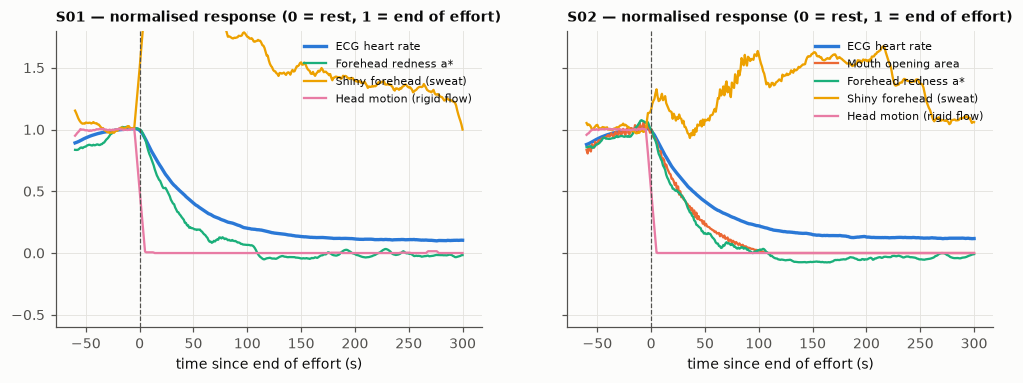

In [13]:
def recovery(d, f, max_s=300):
    """Rest mean, end-of-effort mean, 10-s smoothed series indexed by time since the end of effort, t½ and a note."""
    rest, end = d.loc[d.window == "rest", f], d.loc[(d.window == "effort") & (d.t_since_end >= -30), f].mean()
    s = d.set_index("t_since_end")[f].rolling(10, center=True, min_periods=5).mean().loc[-60:max_s]
    if not np.isfinite(end - rest.mean()):
        return rest.mean(), end, s, np.nan, "no data"
    if abs(end - rest.mean()) < 2 * rest.std():
        return rest.mean(), end, s, np.nan, "no response"
    after = s.loc[0:]
    hit = after[(after - (rest.mean() + end) / 2) * np.sign(end - rest.mean()) <= 0]
    return rest.mean(), end, s, (float(hit.index[0]) if len(hit) else np.nan), ("ok" if len(hit) else f"> {max_s} s")


REC = pd.DataFrame([dict(session=sid, feature=f, **dict(zip(("t_half_s", "note"), recovery(d, f)[3:])))
                    for sid, d in SEC.groupby("session_id") for f in ALL])
REC.to_csv(os.path.join(TAB_DIR, "recovery_half_times.csv"), index=False)
display(REC.pivot(index="feature", columns="session", values=["t_half_s", "note"]).reindex(ALL))

fig, axes = plt.subplots(1, len(sessions), figsize=(5.5 * len(sessions), 3.5), sharey=True, squeeze=False)
for ax, (sid, d) in zip(axes[0], SEC.groupby("session_id")):
    for k, f in enumerate(["hr_ecg", "mouth_area", "forehead_a", "shine_frac", "flow_rigid"]):
        rest, end, s, _, note = recovery(d, f)
        if note != "no data" and end != rest:
            ax.plot(s.index, (s - rest) / (end - rest), color=SERIES[k], lw=2.2 if f == "hr_ecg" else 1.5, label=FEATURE_INFO[f][0])
    ax.axvline(0, color=INK2, ls="--", lw=0.8)
    ax.set(ylim=(-0.6, 1.8), xlabel="time since end of effort (s)")
    ax.set_title(f"{sid} — normalised response (0 = rest, 1 = end of effort)", loc="left")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="upper right", fontsize=7.5)
show(fig, "recovery_curves.png")

## 13. Discussion
*Scaffold: replace each bracket with what your own tables and figures show; never write a conclusion that a table
does not support.* The cell below gathers the key numbers.

**Primary outcome.** [ρ (95 % CI, p) between mouth-opening area and Borg CR10 in each unmasked test, and the pooled
repeated-measures correlation — `primary_outcome.csv`.]
State plainly whether ρ > 0 is supported, and compare with r = 0.70 for *mouth open* vs RPE in Timme & Brand (2020).

**Secondary outcomes.** [Features with |Cliff's δ| ≥ 0.47 and a CI excluding 0 between rest and effort —
`comparisons.csv`.] [Behaviour across the moderate / heavy / severe domains: does mouth opening rise more steeply
above VT1 and VT2, as Timme & Brand hypothesised? — `intensity_domains.csv`, `dose_response_power.png`.]
[Upper-face features in the unmasked vs the masked test at matched power, next to heart rate and Borg —
`matched_stages.csv`.]
[t½ of each feature against heart rate — `recovery_half_times.csv`.]

**What does not work, and why.** [Features without response.] Typical reasons: change smaller than the detector
noise (box jitter at rest), ROI drift with head motion, colour confounded by light or exposure, time constant longer
than a 1-min stage (sweat, redness), occlusion by the mask. Eye openness from the box ratio is constant by
construction (§5).

**Correlation is not causation.** Exercise intensity is a common cause of heart rate, ventilation, mouth opening,
skin blood flow, sweating and head motion, and time is a second one (everything drifts during a ramp). The first
differences (§11), the matched stages (§10) and the recovery (§12) are the analyses that break these confounds.
Other confounders: lighting and exposure, head pose and distance, talking, the fan, sweat on the gray card.

**Limitations.** Two participants, who are the authors: no generalisation, and no blinding to the hypotheses.
[Edit: order of the two tests and time between them — a test that follows a maximal test is not performed fresh.]
VT1/VT2 measured in the masked test are transferred to the unmasked test by power. Mouth and cheeks are hidden by
the mask: the mouth-derived breathing rate is compared with the breathing frequency of the metabolic cart only
across tests. One masked video lacks rest, warm-up and the first stages: no resting reference for that test.
One-minute stages are not steady states. Viola–Jones gives a box, not landmarks: ROIs are fixed proportions of the
box; beard, glasses and hair change the masks. Borg CR10 is discrete and anchored by the previous answers.

**Improvements.** Facial landmarks (lip distance, eye aspect ratio); tracking instead of per-frame detection;
tests on separate days and in random order; several subjects (multilevel models as in Timme & Brand 2020).

In [14]:
print("PRIMARY OUTCOME — mouth area vs Borg CR10:\n", PRIM[["level", "rho", "lo", "hi", "p", "n"]].round(3).to_string(index=False))
key = COMP[(COMP.contrast == "effort vs rest") & COMP.feature.isin(KEY + ["hr_ecg"])]
print("\nEFFORT vs REST (Cliff's δ [95 % CI], Holm p):\n", key[["session", "feature", "cliff_delta", "delta_lo", "delta_hi",
                                                             "mwu_p_holm"]].round(3).to_string(index=False))
print("\nHALF-RECOVERY TIMES (s):\n", REC.pivot(index="feature", columns="session", values="t_half_s").reindex(ALL).to_string())

PRIMARY OUTCOME — mouth area vs Borg CR10:
 level   rho    lo    hi   p  n
  S02 0.983 0.887 0.998 0.0  9

EFFORT vs REST (Cliff's δ [95 % CI], Holm p):
 session     feature  cliff_delta  delta_lo  delta_hi  mwu_p_holm
    S01  forehead_a          1.0       1.0       1.0         0.0
    S01 head_jitter          1.0       1.0       1.0         0.0
    S01      hr_ecg          1.0       1.0       1.0         0.0
    S02  mouth_area          1.0       1.0       1.0         0.0
    S02  forehead_a          1.0       1.0       1.0         0.0
    S02 head_jitter          1.0       1.0       1.0         0.0
    S02      hr_ecg          1.0       1.0       1.0         0.0

HALF-RECOVERY TIMES (s):
 session          S01   S02
feature                   
mouth_area       NaN  26.0
forehead_a      26.0  25.0
head_jitter      0.0   2.0
br_mouth         NaN   NaN
mouth_open_pct   NaN  48.0
cheek_a          NaN  29.0
cheek_hue        NaN  30.0
cheek_sat        NaN  24.0
cheek_val        NaN  25.0
sh

## 14. Reproducibility record
Same parameters for all sequences (`params.json`), fixed seed for every random step, per-frame features cached under
a hash of the parameters and of the video file, all figures and tables written by this notebook.

In [15]:
print(json.dumps(dict(python=platform.python_version(), opencv=cv2.__version__, numpy=np.__version__, pandas=pd.__version__,
                      scipy=scipy.__version__, matplotlib=matplotlib.__version__, seed=SEED, params_hash=PARAM_HASH,
                      sessions=list(sessions.index), seconds=len(SEC)), indent=1))

{
 "python": "3.13.18",
 "opencv": "4.12.0",
 "numpy": "2.2.6",
 "pandas": "3.1.1",
 "scipy": "1.18.1",
 "matplotlib": "3.11.2",
 "seed": 42,
 "params_hash": "fa29e47a",
 "sessions": [
  "S01",
  "S02"
 ],
 "seconds": 1980
}
